# Certified robustness to a geometric transformation and an adversarial patch

Certifies image classifiers against a bounded transformation (rotation, translation, scale) combined with an arbitrary k×k patch, and compares the certificates with an empirical attack.

Contents: 1 Setup, 2 Configuration, 3 Data, 4 Model, 5 Geometry, 6 Threat model, 7 Unit tests, 8 Training, 9 Certifier, 10 Attacks, 11 Range calibration, 12 Joint model, 13 Main experiment, 14 Range study, geometric-only benchmark and search budget, 15 Frontier, 16 Ablations, 17 Window comparison and order (b), 18 Summary.

## 1. Setup

In [1]:
import os, sys, time, json, math, copy, random, itertools
from dataclasses import dataclass, asdict, replace
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib
import matplotlib.pyplot as plt

SEED = 0
def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(SEED)

N_GPU = torch.cuda.device_count()
DEVICES = [torch.device(f"cuda:{i}") for i in range(N_GPU)] or [torch.device("cpu")]
DEV = DEVICES[0]
OUT = "/kaggle/working" if os.path.exists("/kaggle/working") else "./outputs"
os.makedirs(OUT, exist_ok=True)
print("devices:", DEVICES, "| outputs ->", OUT)

devices: [device(type='cuda', index=0), device(type='cuda', index=1)] | outputs -> /kaggle/working


## 2. Configuration

In [2]:
QUICK = False
SYNTHETIC = False
DATASET = "fmnist"  # "mnist", "fmnist" or "cifar10"
ROOT = "/kaggle/working/data" if os.path.exists("/kaggle/working") else "./data"

@dataclass
class Cfg:
    dataset: str = "mnist"
    synthetic: bool = False
    theta_deg: float = 0.5
    tau: float = 0.1
    sigma: float = 0.005
    k: int = 2
    order: str = "a"
    order_b: str = "weighted"
    epochs: int = 30
    warmup: int = 2
    ramp: int = 10
    bs: int = 128
    lr: float = 1e-3
    clean_w_end: float = 0.5
    train_fracs: tuple = (0.125, 0.25, 0.5, 1.0)
    train_locs: int = 4
    n_train: int = 0
    n_val: int = 2000
    seed: int = 0
    max_depth: int = 8
    max_nodes: int = 600
    chunk: int = 2048
    taylor: bool = False
    falsify_n: int = 32
    use_crown: bool = False
    crown_chunk: int = 128
    mask_stride: int = 6
    n_eval: int = 500
    n_abl: int = 300
    n_seeds: int = 3
    att_kappa: int = 24
    att_stride: int = 1
    att_steps: int = 10
    prescreen: bool = False

def make_cfg(dataset, quick):
    if dataset in ("mnist", "fmnist"):
        c = Cfg(dataset=dataset)
    else:
        c = Cfg(dataset="cifar10", epochs=60, ramp=20, att_kappa=18, att_stride=2)
    if quick:
        c = replace(c, epochs=8, warmup=2, ramp=4, n_train=20000, n_val=1000, max_depth=5, max_nodes=100, train_locs=2,
                    n_eval=20, n_abl=10, n_seeds=2, att_kappa=8, att_stride=2, att_steps=5)
    return replace(c, synthetic=SYNTHETIC)

cfg = make_cfg(DATASET, QUICK)
print(cfg)

Cfg(dataset='fmnist', synthetic=False, theta_deg=0.5, tau=0.1, sigma=0.005, k=2, order='a', order_b='weighted', epochs=30, warmup=2, ramp=10, bs=128, lr=0.001, clean_w_end=0.5, train_fracs=(0.125, 0.25, 0.5, 1.0), train_locs=4, n_train=0, n_val=2000, seed=0, max_depth=8, max_nodes=600, chunk=2048, taylor=False, falsify_n=32, use_crown=False, crown_chunk=128, mask_stride=6, n_eval=500, n_abl=300, n_seeds=3, att_kappa=24, att_stride=1, att_steps=10, prescreen=False)


## 3. Data

In [3]:
def load_data(cfg):
    if cfg.synthetic:
        g = torch.Generator().manual_seed(0)
        H = W = 32 if cfg.dataset == "cifar10" else 28
        C = 3 if cfg.dataset == "cifar10" else 1
        def gen(n):
            y = torch.randint(0, 10, (n,), generator=g)
            ys, xs = torch.meshgrid(torch.arange(H).float(), torch.arange(W).float(), indexing="ij")
            X = torch.zeros(n, C, H, W)
            for i in range(n):
                cy = 6 + 2 * (int(y[i]) // 5) * 4 + 0.0
                cx = 4 + 2.2 * (int(y[i]) % 5) * 2.4
                X[i] = torch.exp(-((ys - cy) ** 2 + (xs - cx) ** 2) / 8.0)
            return (X + 0.03 * torch.randn(n, C, H, W, generator=g)).clamp(0, 1), y
        Xtr, ytr = gen(6000); Xte, yte = gen(1000)
        return Xtr, ytr, Xte, yte
    from torchvision import datasets
    os.makedirs(ROOT, exist_ok=True)
    if cfg.dataset in ("mnist", "fmnist"):
        D = datasets.MNIST if cfg.dataset == "mnist" else datasets.FashionMNIST
        tr = D(ROOT, train=True, download=True); te = D(ROOT, train=False, download=True)
        f = lambda d: (d.data.float().div(255).unsqueeze(1), d.targets.long())
    else:
        tr = datasets.CIFAR10(ROOT, train=True, download=True); te = datasets.CIFAR10(ROOT, train=False, download=True)
        f = lambda d: (torch.tensor(d.data).permute(0, 3, 1, 2).float().div(255), torch.tensor(d.targets).long())
    Xtr, ytr = f(tr); Xte, yte = f(te)
    return Xtr, ytr, Xte, yte

Xtr, ytr, Xte, yte = load_data(cfg)
Xval, yval = Xtr[-cfg.n_val:], ytr[-cfg.n_val:]
Xtr, ytr = Xtr[:-cfg.n_val], ytr[:-cfg.n_val]
if cfg.n_train: Xtr, ytr = Xtr[:cfg.n_train], ytr[:cfg.n_train]
EVAL_IDX = np.random.RandomState(1234).permutation(len(Xte))
print(Xtr.shape, Xval.shape, Xte.shape)

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 202kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.74MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 12.2MB/s]


torch.Size([58000, 1, 28, 28]) torch.Size([2000, 1, 28, 28]) torch.Size([10000, 1, 28, 28])


## 4. Model

In [4]:
class Norm(nn.Module):
    def __init__(self, mean, std):
        super().__init__()
        self.register_buffer("mean", torch.tensor(mean).view(1, -1, 1, 1))
        self.register_buffer("std", torch.tensor(std).view(1, -1, 1, 1))
    def forward(self, x): return (x - self.mean) / self.std

def ibp_layer(l, lb, ub):
    if isinstance(l, (nn.Conv2d, nn.Linear)):
        mu, r = (lb + ub) / 2, (ub - lb) / 2
        if isinstance(l, nn.Conv2d):
            mu2 = F.conv2d(mu, l.weight, l.bias, l.stride, l.padding)
            r2 = F.conv2d(r, l.weight.abs(), None, l.stride, l.padding)
        else:
            mu2 = F.linear(mu, l.weight, l.bias); r2 = F.linear(r, l.weight.abs())
        return mu2 - r2, mu2 + r2
    if isinstance(l, nn.ReLU): return F.relu(lb), F.relu(ub)
    if isinstance(l, nn.Flatten): return lb.flatten(1), ub.flatten(1)
    if isinstance(l, Norm): return l(lb), l(ub)
    raise ValueError(f"unsupported layer {type(l)}")

class IBPNet(nn.Module):
    def __init__(self, layers):
        super().__init__()
        self.layers = nn.ModuleList(layers)
        assert isinstance(self.layers[-1], nn.Linear)
    def forward(self, x):
        for l in self.layers: x = l(x)
        return x
    def margin_lb(self, lb, ub, y, start=0):
        for l in self.layers[start:-1]: lb, ub = ibp_layer(l, lb, ub)
        W, b = self.layers[-1].weight, self.layers[-1].bias
        Wd = W[y].unsqueeze(1) - W.unsqueeze(0)
        bd = b[y].unsqueeze(1) - b.unsqueeze(0)
        mu, r = ((lb + ub) / 2).flatten(1), ((ub - lb) / 2).flatten(1)
        return torch.einsum("bjd,bd->bj", Wd, mu) + bd - torch.einsum("bjd,bd->bj", Wd.abs(), r)

def verified_from_margins(m, y):
    m = m.masked_fill(F.one_hot(y, m.size(1)).bool(), float("inf"))
    return (m > 0).all(1)

def build_model(cfg):
    if cfg.dataset in ("mnist", "fmnist"):
        mu, sd = ([0.1307], [0.3081]) if cfg.dataset == "mnist" else ([0.2860], [0.3530])
        L = [Norm(mu, sd),
             nn.Conv2d(1, 16, 4, 2, 1), nn.ReLU(), nn.Conv2d(16, 32, 4, 2, 1), nn.ReLU(),
             nn.Flatten(), nn.Linear(32 * 7 * 7, 100), nn.ReLU(), nn.Linear(100, 10)]
    else:
        L = [Norm([0.4914, 0.4822, 0.4465], [0.2470, 0.2435, 0.2616]),
             nn.Conv2d(3, 32, 3, 1, 1), nn.ReLU(), nn.Conv2d(32, 32, 4, 2, 1), nn.ReLU(),
             nn.Conv2d(32, 64, 3, 1, 1), nn.ReLU(), nn.Conv2d(64, 64, 4, 2, 1), nn.ReLU(),
             nn.Flatten(), nn.Linear(64 * 8 * 8, 512), nn.ReLU(), nn.Linear(512, 10)]
    return IBPNet(L)

print(sum(p.numel() for p in build_model(cfg).parameters()), "parameters")

166406 parameters


## 5. Geometry

Centred pixel coordinates; the source point of output pixel p is q = R(θ)p / s + t, sampled bilinearly with zero padding. Over a box of κ = (θ, Δx, Δy, s) each pixel gets an interval from the bilinear weights (a hull that converges as the box shrinks). `make_taylor` adds an optional first-order Taylor model with a Lagrange remainder for pixels whose bilinear cell is fixed over the box.

In [5]:
def _grid(H, W, dev):
    cy, cx = (H - 1) / 2, (W - 1) / 2
    ys, xs = torch.meshgrid(torch.arange(H, dtype=torch.float64, device=dev) - cy,
                            torch.arange(W, dtype=torch.float64, device=dev) - cx, indexing="ij")
    return ys, xs, cy, cx

def warp(x, kappa):
    # x: (B,C,H,W); kappa: (B,4) or (4,) = (theta[rad], tx, ty, s). Bilinear, zero padding. Differentiable wrt x and kappa.
    B, C, H, W = x.shape
    kappa = kappa.to(device=x.device, dtype=torch.float64)
    if kappa.dim() == 1: kappa = kappa.unsqueeze(0).expand(B, 4)
    ys, xs, cy, cx = _grid(H, W, x.device)
    th, tx, ty, s = [kappa[:, i].view(B, 1, 1) for i in range(4)]
    c, sn = torch.cos(th), torch.sin(th)
    qx = (c * xs - sn * ys) / s + tx + cx
    qy = (sn * xs + c * ys) / s + ty + cy
    x0, y0 = torch.floor(qx), torch.floor(qy)
    wx, wy = (qx - x0).to(x.dtype).unsqueeze(1), (qy - y0).to(x.dtype).unsqueeze(1)
    xp = F.pad(x, (1, 1, 1, 1)).reshape(B, C, -1)
    def g(yi, xi):
        yi = (yi.long() + 1).clamp(0, H + 1); xi = (xi.long() + 1).clamp(0, W + 1)
        idx = (yi * (W + 2) + xi).view(B, 1, H * W).expand(B, C, H * W)
        return xp.gather(2, idx).view(B, C, H, W)
    return (g(y0, x0) * (1 - wx) * (1 - wy) + g(y0, x0 + 1) * wx * (1 - wy)
            + g(y0 + 1, x0) * (1 - wx) * wy + g(y0 + 1, x0 + 1) * wx * wy)

def cos_range(a, b):
    ca, cb = torch.cos(a), torch.cos(b)
    hi, lo = torch.maximum(ca, cb), torch.minimum(ca, cb)
    tp = 2 * math.pi
    has_max = torch.floor(b / tp) >= torch.ceil(a / tp)
    has_min = torch.floor((b - math.pi) / tp) >= torch.ceil((a - math.pi) / tp)
    return torch.where(has_min, -torch.ones_like(lo), lo), torch.where(has_max, torch.ones_like(hi), hi)

def rot_intervals(H, W, box, dev):
    t0, t1 = box[0]
    ys, xs, cy, cx = _grid(H, W, dev)
    r, phi = torch.sqrt(xs ** 2 + ys ** 2), torch.atan2(ys, xs)
    cl, ch = cos_range(phi + t0, phi + t1)
    sl, sh = cos_range(phi + t0 - math.pi / 2, phi + t1 - math.pi / 2)
    return r * cl, r * ch, r * sl, r * sh

def src_interval(H, W, box, dev):
    # box = [(t0,t1),(a0,a1),(b0,b1),(s0,s1)] python floats. Per-output-pixel intervals of source index coordinates.
    (t0, t1), (a0, a1), (b0, b1), (s0, s1) = box
    cy, cx = (H - 1) / 2, (W - 1) / 2
    xl, xh, yl, yh = rot_intervals(H, W, box, dev)
    i0, i1 = 1.0 / s1, 1.0 / s0
    def ivmul(lo, hi):
        c = torch.stack([lo * i0, lo * i1, hi * i0, hi * i1]); return c.min(0).values, c.max(0).values
    xl, xh = ivmul(xl, xh); yl, yh = ivmul(yl, yh)
    return xl + a0 + cx, xh + a1 + cx, yl + b0 + cy, yh + b1 + cy

def _hat(d): return (1 - d.abs()).clamp(0, 1)

def make_node(x, box, keep_offs=False):
    B, C, H, W = x.shape
    qx0, qx1, qy0, qy1 = src_interval(H, W, box, x.device)
    ix0, iy0 = torch.floor(qx0 + 1e-9).long(), torch.floor(qy0 + 1e-9).long()
    ix1 = torch.maximum(torch.ceil(qx1 - 1e-9).long(), ix0); iy1 = torch.maximum(torch.ceil(qy1 - 1e-9).long(), iy0)
    Kx, Ky = int((ix1 - ix0).max()) + 1, int((iy1 - iy0).max()) + 1
    xp = F.pad(x, (1, 1, 1, 1)).reshape(B, C, -1)
    acc = torch.zeros_like(x); sw = torch.zeros(H, W, dtype=x.dtype, device=x.device)
    big, small = torch.tensor(2.0, dtype=x.dtype, device=x.device), torch.tensor(-1.0, dtype=x.dtype, device=x.device)
    mn, mx = torch.full_like(x, 2.0), torch.full_like(x, -1.0); offs = []
    for dy in range(Ky):
        ay = iy0 + dy; wy = torch.minimum(_hat(qy0 - ay), _hat(qy1 - ay)); vy = dy <= (iy1 - iy0)
        for dx in range(Kx):
            ax = ix0 + dx; valid = vy & (dx <= (ix1 - ix0))
            w = (torch.minimum(_hat(qx0 - ax), _hat(qx1 - ax)) * wy * valid).to(x.dtype)
            yy, xx = (ay + 1).clamp(0, H + 1), (ax + 1).clamp(0, W + 1)
            v = xp.gather(2, (yy * (W + 2) + xx).view(1, 1, -1).expand(B, C, -1)).view(B, C, H, W)
            acc = acc + w * v; sw = sw + w
            mn = torch.minimum(mn, torch.where(valid, v, big)); mx = torch.maximum(mx, torch.where(valid, v, small))
            if keep_offs: offs.append((v, w, valid, ay, ax))
    rest = (1 - sw).clamp_min(0)
    return dict(lb=acc + rest * mn, ub=acc + rest * mx, offs=offs, sw=sw, qx0=qx0, qx1=qx1, qy0=qy0, qy1=qy1)

def geom_bounds(x, box):
    n = make_node(x, box); return n["lb"], n["ub"]

def _imul(alo, ahi, blo, bhi):
    c = torch.stack(torch.broadcast_tensors(alo * blo, alo * bhi, ahi * blo, ahi * bhi))
    return c.min(0).values, c.max(0).values

def make_taylor(x, box, node):
    # First-order Taylor model of warp(x, kappa) over kappa in box with a rigorous Lagrange remainder.
    #   warp(x, kappa) in centre + sum_i G_i z_i +- err,   z_i = (kappa_i - mid_i) / halfwidth_i in [-1,1].
    B, C, H, W = x.shape; dev = x.device
    mid = [(a + b) / 2 for a, b in box]; wid = [(b - a) / 2 for a, b in box]
    qx0, qx1, qy0, qy1 = node["qx0"], node["qx1"], node["qy0"], node["qy1"]
    x0, y0 = torch.floor(qx0 + 1e-9), torch.floor(qy0 + 1e-9)               # 1e-9: pixel centres sit exactly on cell edges at kappa=0
    fixed = (qx1 <= x0 + 1 + 1e-9) & (qy1 <= y0 + 1 + 1e-9)
    xp = F.pad(x.double(), (1, 1, 1, 1)).reshape(B, C, -1)
    def gat(yi, xi):
        yy, xx = (yi.long() + 1).clamp(0, H + 1), (xi.long() + 1).clamp(0, W + 1)
        return xp.gather(2, (yy * (W + 2) + xx).view(1, 1, -1).expand(B, C, -1)).view(B, C, H, W)
    p00, p10, p01, p11 = gat(y0, x0), gat(y0, x0 + 1), gat(y0 + 1, x0), gat(y0 + 1, x0 + 1)
    D1, D2, Dd = p10 - p00, p01 - p00, p00 - p10 - p01 + p11
    ys, xs, cy, cx = _grid(H, W, dev)
    th, tx, ty, sc = mid; rho = 1.0 / sc
    r1 = math.cos(th) * xs - math.sin(th) * ys; r2 = math.sin(th) * xs + math.cos(th) * ys
    uc = r1 * rho + tx + cx - x0; vc = r2 * rho + ty + cy - y0
    fu, fv = D1 + Dd * vc, D2 + Dd * uc
    gc = p00 + D1 * uc + D2 * vc + Dd * uc * vc
    G = torch.stack([fu * (-r2 * rho) + fv * (r1 * rho), fu, fv, fu * (-r1 * rho ** 2) + fv * (-r2 * rho ** 2)])
    xl, xh, yl, yh = rot_intervals(H, W, box, dev)
    rho0, rho1 = 1.0 / box[3][1], 1.0 / box[3][0]
    Z, O = torch.zeros(H, W, dtype=torch.float64, device=dev), torch.ones(H, W, dtype=torch.float64, device=dev)
    c = lambda t: torch.tensor(t, dtype=torch.float64, device=dev)
    R1, R2, R3 = (c(rho0), c(rho1)), (c(rho0 ** 2), c(rho1 ** 2)), (c(rho0 ** 3), c(rho1 ** 3))
    dqx = [_imul(-yh, -yl, *R1), (O, O), (Z, Z), _imul(-xh, -xl, *R2)]
    dqy = [_imul(xl, xh, *R1), (Z, Z), (O, O), _imul(-yh, -yl, *R2)]
    two = lambda t: (2 * t[0], 2 * t[1])
    d2x = {(0, 0): _imul(-xh, -xl, *R1), (0, 3): _imul(yl, yh, *R2), (3, 3): two(_imul(xl, xh, *R3))}
    d2y = {(0, 0): _imul(-yh, -yl, *R1), (0, 3): _imul(-xh, -xl, *R2), (3, 3): two(_imul(yl, yh, *R3))}
    ulo, uhi, vlo, vhi = qx0 - x0, qx1 - x0, qy0 - y0, qy1 - y0
    def lin_iv(D0, Dt, lo, hi):
        a, b = Dt * lo, Dt * hi; return D0 + torch.minimum(a, b), D0 + torch.maximum(a, b)
    fu_lo, fu_hi = lin_iv(D1, Dd, vlo, vhi); fv_lo, fv_hi = lin_iv(D2, Dd, ulo, uhi)
    err = torch.zeros(1, C, H, W, dtype=torch.float64, device=dev)
    for i in range(4):
        for j in range(i, 4):
            a, b = _imul(*dqx[i], *dqy[j]), _imul(*dqy[i], *dqx[j])
            t1 = _imul(Dd, Dd, a[0] + b[0], a[1] + b[1])
            t2 = _imul(fu_lo, fu_hi, *d2x.get((i, j), (Z, Z))); t3 = _imul(fv_lo, fv_hi, *d2y.get((i, j), (Z, Z)))
            hmax = torch.maximum((t1[0] + t2[0] + t3[0]).abs(), (t1[1] + t2[1] + t3[1]).abs())
            err = err + (0.5 if i == j else 1.0) * hmax * wid[i] * wid[j]
    fx = fixed.view(1, 1, H, W); mlb, mub = node["lb"].double(), node["ub"].double()
    centre = torch.where(fx, gc, (mlb + mub) / 2)
    G = torch.where(fx[None], G, torch.zeros_like(G)) * torch.tensor(wid, dtype=torch.float64, device=dev).view(4, 1, 1, 1, 1)
    err = torch.where(fx, err, (mub - mlb) / 2)
    return dict(center=centre.to(x.dtype), G=G.to(x.dtype), err=(err + 1e-6).to(x.dtype), fixed=fixed)

def footprint(node, locs, k):
    i, j = locs[:, 0].double()[:, None, None], locs[:, 1].double()[:, None, None]
    ax = (node["qx1"][None] > j - 1 - 1e-9) & (node["qx0"][None] < j + k + 1e-9)
    ay = (node["qy1"][None] > i - 1 - 1e-9) & (node["qy0"][None] < i + k + 1e-9)
    return (ax & ay).unsqueeze(1)

def bounds_b(node, locs, k, variant):
    lb, ub = node["lb"], node["ub"]; aff = footprint(node, locs, k)
    if variant == "footprint":
        Mf = aff.to(lb.dtype); return lb * (1 - Mf), ub * (1 - Mf) + Mf
    n, C, H, W = len(locs), lb.size(1), lb.size(2), lb.size(3)
    zero, one = torch.zeros((), dtype=lb.dtype, device=lb.device), torch.ones((), dtype=lb.dtype, device=lb.device)
    big, small = 2 * one, -1 * one
    acc = torch.zeros(n, C, H, W, dtype=lb.dtype, device=lb.device); swp = torch.zeros(n, 1, H, W, dtype=lb.dtype, device=lb.device)
    mn, mx = torch.full_like(acc, 2.0), torch.full_like(acc, -1.0)
    ii, jj = locs[:, 0, None, None], locs[:, 1, None, None]
    for (v, w, valid, ay, ax) in node["offs"]:
        inp = ((ay[None] >= ii) & (ay[None] < ii + k) & (ax[None] >= jj) & (ax[None] < jj + k)).unsqueeze(1)
        wf = w[None, None]; ok = valid[None, None] & ~inp
        acc = acc + (wf * (~inp)) * v; swp = swp + wf * inp
        ve = v.expand(n, -1, -1, -1)
        mn = torch.minimum(mn, torch.where(ok, ve, big)); mx = torch.maximum(mx, torch.where(ok, ve, small))
    rest = (1 - node["sw"])[None, None].clamp_min(0)
    Lw = acc + rest * torch.minimum(mn, zero); Uw = acc + swp + rest * torch.maximum(mx, one)
    return torch.where(aff, Lw, lb), torch.where(aff, Uw, ub)

def kbox(cfg, identity=False):
    if identity: return [(0.0, 0.0), (0.0, 0.0), (0.0, 0.0), (1.0, 1.0)]
    t = math.radians(cfg.theta_deg)
    return [(-t, t), (-cfg.tau, cfg.tau), (-cfg.tau, cfg.tau), (1 - cfg.sigma, 1 + cfg.sigma)]

def box_pixel_widths(box, H, W):
    rmax = math.sqrt(((H - 1) / 2) ** 2 + ((W - 1) / 2) ** 2)
    (t0, t1), (a0, a1), (b0, b1), (s0, s1) = box
    return [rmax * (t1 - t0), a1 - a0, b1 - b0, rmax * (1 / s0 - 1 / s1)]

def split_box(box, dim):
    lo, hi = box[dim]; mid = (lo + hi) / 2
    b1, b2 = list(box), list(box); b1[dim] = (lo, mid); b2[dim] = (mid, hi)
    return b1, b2

def rand_kappa(box, B, dev=None):
    lo = torch.tensor([b[0] for b in box], dtype=torch.float64); hi = torch.tensor([b[1] for b in box], dtype=torch.float64)
    k = lo + torch.rand(B, 4, dtype=torch.float64) * (hi - lo)
    return k.to(dev) if dev is not None else k

def random_subbox(box, frac):
    out = []
    for lo, hi in box:
        w = (hi - lo) * frac; s = lo + random.random() * ((hi - lo) - w); out.append((s, s + w))
    return out

def box_corners(box):
    return torch.tensor(list(itertools.product(*box)), dtype=torch.float64)

print("geometry ok")

geometry ok


## 6. Threat model

Order (a): the patch is applied after the transform. Order (b): the patch is applied before the transform and moves with the image. Order (b) is certified in one of three ways: `lemma` (patch of side S = ⌈s_max (k+1)(cos θ₀ + sin θ₀)⌉ after the transform), `footprint` (the output pixels the patch can touch) or `weighted` (touched pixels keep their image content). The mask set is a PatchCleanser-style covering set of squares of side k + stride − 1.

In [6]:
def effective_patch(cfg):
    # patch side to certify with in output coordinates: k for order (a), S (lemma) for order (b)
    if cfg.order == "a": return cfg.k
    t0 = math.radians(cfg.theta_deg)
    f = (math.cos(t0) + math.sin(t0)) if t0 <= math.pi / 4 else math.sqrt(2)
    return int(math.ceil((1 + cfg.sigma) * (cfg.k + 1) * f - 1e-12))

def all_locs(H, W, k, stride=1, dev=None):
    ii = torch.arange(0, H - k + 1, stride); jj = torch.arange(0, W - k + 1, stride)
    L = torch.stack(torch.meshgrid(ii, jj, indexing="ij"), -1).reshape(-1, 2)
    return L.to(dev) if dev is not None else L

def masks_from_locs(locs, k, H, W):
    r = torch.arange(H, device=locs.device)[None, :, None]; c = torch.arange(W, device=locs.device)[None, None, :]
    i, j = locs[:, 0, None, None], locs[:, 1, None, None]
    return ((r >= i) & (r < i + k) & (c >= j) & (c < j + k)).unsqueeze(1)

def rand_masks(B, k, H, W, dev):
    locs = torch.stack([torch.randint(0, H - k + 1, (B,)), torch.randint(0, W - k + 1, (B,))], 1).to(dev)
    return masks_from_locs(locs, k, H, W)

_MASKS = {}
def get_mask_set(H, W, k, stride, dev):
    # (M,1,H,W) float, 1 = masked. R-covering for k x k patches.
    key = (H, W, k, stride, str(dev))
    if key not in _MASKS:
        w = min(k + stride - 1, H, W)
        def starts(n):
            s = list(range(0, n - w + 1, stride))
            if s[-1] != n - w: s.append(n - w)
            return s
        r = torch.arange(H)[:, None]; c = torch.arange(W)[None, :]
        ms = [(((r >= a) & (r < a + w)) & ((c >= b) & (c < b + w))).float() for a in starts(H) for b in starts(W)]
        _MASKS[key] = torch.stack(ms).unsqueeze(1).to(dev)
    return _MASKS[key]

print("k_eff for order (b) at current cfg:", effective_patch(replace(cfg, order="b")),
      "| mask-set size:", len(get_mask_set(28, 28, cfg.k, cfg.mask_stride, "cpu")))

k_eff for order (b) at current cfg: 4 | mask-set size: 25


## 7. Unit tests

In [7]:
def test_warp_bounds(n_img=4, n_box=6, n_samp=300):
    x = Xte[:n_img].to(DEV); worst = 0.0
    for _ in range(n_box):
        box = random_subbox(kbox(cfg), random.choice([0.1, 0.5, 1.0]))
        lb, ub = geom_bounds(x, box)
        ks = torch.cat([box_corners(box), rand_kappa(box, n_samp)])
        for kk in ks:
            t = warp(x, kk); worst = max(worst, float((lb - t).max()), float((t - ub).max()))
    print("max violation of warp bounds:", worst); assert worst < 1e-5, "warp bounds unsound"
    lb, ub = geom_bounds(x, kbox(cfg, identity=True))
    assert float((ub - lb).abs().max()) < 1e-6, "identity box must be exact"
    widths = []
    for frac in [1.0, 0.25, 0.0625, 0.0156]:
        ws = []
        for _ in range(6):
            lb, ub = geom_bounds(x, random_subbox(kbox(cfg), frac)); ws.append(float((ub - lb).mean()))
        widths.append(np.mean(ws))
    print("mean bound width at box fractions [1, 1/4, 1/16, 1/64]:", np.round(widths, 4))
    assert widths[-1] < 0.6 * widths[0] and widths[-1] < widths[-2] + 1e-6, "bounds do not converge"

@torch.no_grad()
def test_ibp(n_samp=200):
    net = build_model(cfg).to(DEV).eval()
    x = Xte[:3].to(DEV); y = yte[:3].to(DEV); H, W = x.shape[-2:]
    box = random_subbox(kbox(cfg), 0.5); k = cfg.k
    lb, ub = geom_bounds(x, box)
    loc = torch.tensor([[3, 4]], device=DEV); M = masks_from_locs(loc, k, H, W).float()
    m = net.margin_lb(lb * (1 - M), ub * (1 - M) + M, y); worst = -1e9
    for _ in range(n_samp):
        kk = rand_kappa(box, 1, DEV)[0]; p = torch.rand_like(x)
        z = net(warp(x, kk) * (1 - M) + p * M)
        worst = max(worst, float((m - (z.gather(1, y[:, None]) - z)).max()))
    print("max (lower bound - actual margin):", worst); assert worst < 1e-3, "IBP unsound"

@torch.no_grad()
def test_order_b(n=200, n_loc=6):
    cc = replace(cfg, order="b"); S = effective_patch(cc); k = cfg.k
    x = Xte[:1].to(DEV); H, W = x.shape[-2:]; worst_span = 0
    for _ in range(n):
        box = random_subbox(kbox(cfg), random.choice([0.2, 1.0])); node = make_node(x, box)
        kk = rand_kappa(box, 1, DEV)[0]
        loc = torch.tensor([[random.randint(0, H - k), random.randint(0, W - k)]], device=DEV)
        M = masks_from_locs(loc, k, H, W).float()
        outs = [warp(x * (1 - M) + torch.rand_like(x) * M, kk) for _ in range(2)]
        d = ((outs[0] - outs[1]).abs().amax(1)[0] > 1e-7)
        if d.any():
            rows, cols = d.any(1).nonzero().flatten(), d.any(0).nonzero().flatten()
            worst_span = max(worst_span, int(rows.max() - rows.min() + 1), int(cols.max() - cols.min() + 1))
            fp = footprint(node, loc, k)[0, 0]; assert bool((d & ~fp).sum() == 0), "footprint misses a changed pixel"
    print(f"largest changed span = {worst_span} px, lemma S = {S}"); assert worst_span <= S, "lemma violated"
    for variant in ("footprint", "weighted"):
        worst, wsum = 0.0, {}
        for _ in range(8):
            box = random_subbox(kbox(cfg), random.choice([0.2, 0.6])); node = make_node(x, box, keep_offs=True)
            locs = torch.stack([torch.randint(0, H - k + 1, (n_loc,)), torch.randint(0, W - k + 1, (n_loc,))], 1).to(DEV)
            L, U = bounds_b(node, locs, k, variant); M = masks_from_locs(locs, k, H, W).float()
            for _ in range(60):
                kk = rand_kappa(box, 1, DEV)[0]
                out = warp(x * (1 - M) + torch.rand(n_loc, *x.shape[1:], device=DEV) * M, kk)
                worst = max(worst, float((L - out).max()), float((out - U).max()))
            wsum[variant] = wsum.get(variant, 0) + float((U - L).mean())
        print(f"order (b) {variant}: max violation {worst:.2e}"); assert worst < 1e-5, f"{variant} unsound"
    box = random_subbox(kbox(cfg), 0.5); node = make_node(x, box, keep_offs=True)
    locs = all_locs(H, W, k, 3, DEV)
    Lf, Uf = bounds_b(node, locs, k, "footprint"); Lw, Uw = bounds_b(node, locs, k, "weighted")
    print("mean width footprint vs weighted:", round(float((Uf - Lf).mean()), 4), round(float((Uw - Lw).mean()), 4))
    assert float((Lw - Lf).min()) > -1e-5 and float((Uf - Uw).min()) > -1e-5, "weighted looser than footprint"

@torch.no_grad()
def test_masks():
    for k in (1, 2, 3):
        H, W = Xte.shape[-2:]; ms = get_mask_set(H, W, k, cfg.mask_stride, "cpu") > 0.5
        pm = masks_from_locs(all_locs(H, W, k), k, H, W)
        for s in range(0, len(pm), 100):
            unc = (pm[s:s + 100, None] & ~ms[None]).flatten(2).any(2)
            assert bool((~unc).any(1).all()), f"mask set is not covering for k={k}"
    print("mask sets are R-covering for k=1,2,3")

@torch.no_grad()
def test_taylor(n_samp=60):
    x = Xte[:1].to(DEV); H, W = x.shape[-2:]; worst = -1e9; fixed_fracs = []; gain = []
    t0 = math.radians(cfg.theta_deg); tau, sg = cfg.tau, cfg.sigma
    boxes = [random_subbox(kbox(cfg), f) for f in (0.05, 0.25, 1.0)]
    boxes += [[(0.3 * t0, 0.5 * t0), (0.2 * tau, 0.4 * tau), (0.1 * tau, 0.3 * tau), (1 + 0.2 * sg, 1 + 0.4 * sg)],
              [(0.0, 0.1 * t0), (0.0, 0.1 * tau), (0.0, 0.1 * tau), (1.0, 1 + 0.1 * sg)],
              [(0.5 * t0, 0.8 * t0), (0.5 * tau, 0.8 * tau), (0.5 * tau, 0.8 * tau), (1 + 0.5 * sg, 1 + 0.8 * sg)]]
    for box in boxes:
        node = make_node(x, box); T = make_taylor(x, box, node); fx = T["fixed"]; fixed_fracs.append(float(fx.float().mean()))
        mid = torch.tensor([(a + b) / 2 for a, b in box], dtype=torch.float64, device=DEV)
        wid = torch.tensor([(b - a) / 2 for a, b in box], dtype=torch.float64, device=DEV)
        ks = torch.cat([box_corners(box).to(DEV), rand_kappa(box, n_samp, DEV)])
        for kk in ks:
            z = torch.where(wid > 0, (kk - mid) / wid.clamp_min(1e-12), torch.zeros_like(wid))
            approx = T["center"] + (T["G"] * z.view(4, 1, 1, 1, 1).to(x.dtype)).sum(0)
            viol = ((warp(x, kk) - approx).abs() - T["err"])[:, :, fx]
            if viol.numel(): worst = max(worst, float(viol.max()))
        if fx.any():
            hull = (node["ub"] - node["lb"])[:, :, fx].mean(); tay = (2 * (T["G"].abs().sum(0) + T["err"]))[:, :, fx].mean()
            gain.append((int(fx.sum()), float(hull), float(tay)))
    print("fraction of cell-fixed pixels per test box:", np.round(fixed_fracs, 3))
    print("(n cell-fixed pixels, mean hull width, mean Taylor width) per box that has any:", [(n, round(a, 4), round(b, 4)) for n, a, b in gain])
    print("Taylor model on cell-fixed pixels: max (|warp - model| - err) =", worst)
    assert max(fixed_fracs) > 0.2, "test is vacuous: no cell-fixed pixels were exercised"
    assert worst < 1e-5, "Taylor model unsound"
    net = build_model(cfg).to(DEV).eval(); box = boxes[3]
    node = make_node(x, box); T = make_taylor(x, box, node)
    M = masks_from_locs(torch.tensor([[3, 4]], device=DEV), cfg.k, H, W).float(); keep = 1 - M
    lbT, ubT = taylor_first_layer(net, T, keep, 0.5, 0.5)
    lbP, ubP = ibp_layer(net.layers[1], *ibp_layer(net.layers[0], node["lb"] * keep, node["ub"] * keep + M))
    viol = 0.0
    for _ in range(100):
        kk = rand_kappa(box, 1, DEV)[0]; f1 = net.layers[1](net.layers[0](warp(x, kk) * keep + torch.rand_like(x) * M))
        viol = max(viol, float((lbT - f1).max()), float((f1 - ubT).max()))
    print(f"first-layer bounds (away-from-identity box): violation {viol:.2e}; mean width Taylor {float((ubT-lbT).mean()):.4f} vs pixel {float((ubP-lbP).mean()):.4f}")
    assert viol < 1e-4, "Taylor first layer unsound"

class _Const(nn.Module):
    def __init__(self, c): super().__init__(); self.c = c
    def forward(self, x): return F.one_hot(torch.full((x.size(0),), self.c, device=x.device), 10).float()

@torch.no_grad()
def test_falsify_and_pc():
    net = build_model(cfg).to(DEV).eval(); x = Xte[:1].to(DEV)
    y_wrong = (net(x).argmax(1) + 1) % 10
    ok, nodes = certify_cfg(net, x, y_wrong, replace(cfg, falsify_n=8, max_depth=6), "transform")
    print("falsification on a wrong label: certified", ok, "nodes", nodes); assert (not ok) and nodes == 1
    mset = get_mask_set(*x.shape[-2:], cfg.k, cfg.mask_stride, DEV)
    assert pc_predict(_Const(3), x, mset) == 3, "double-masking must return the agreed label"
    print("PatchCleanser inference: agreed-label case ok")

test_warp_bounds(); test_ibp(); test_order_b(); test_masks(); print("geometry/bound unit tests passed (Taylor and certifier tests run after section 9)")

max violation of warp bounds: 1.7881393432617188e-07
mean bound width at box fractions [1, 1/4, 1/16, 1/64]: [0.0945 0.0326 0.0077 0.0018]
max (lower bound - actual margin): 0.0
largest changed span = 4 px, lemma S = 4
order (b) footprint: max violation 0.00e+00
order (b) weighted: max violation 0.00e+00
mean width footprint vs weighted: 0.0539 0.0426
mask sets are R-covering for k=1,2,3
geometry/bound unit tests passed (Taylor and certifier tests run after section 9)


## 8. Training

In [8]:
def ckpt_tag(cfg, mode):
    # checkpoint name that changes whenever anything that affects the trained model changes
    import hashlib
    keys = ["dataset", "epochs", "warmup", "ramp", "bs", "lr", "n_train", "n_val", "seed"]
    if mode != "standard": keys += ["order", "theta_deg", "tau", "sigma", "k", "clean_w_end", "train_fracs", "train_locs"]
    if mode == "mask": keys += ["mask_stride"]
    if mode == "patch": keys = [k for k in keys if k not in ("theta_deg", "tau", "sigma")]
    if mode == "transform": keys = [k for k in keys if k != "k"]
    sig = hashlib.md5(json.dumps({k: getattr(cfg, k) for k in keys}, sort_keys=True, default=str).encode()).hexdigest()[:8]
    return f"{cfg.dataset}_{mode}_{cfg.order if mode != 'standard' else 'x'}_{sig}"

def train_model(cfg, mode, Xtr, ytr, Xv, yv, tag, resume=True, verbose=True):
    assert mode in ("standard", "transform", "patch", "joint", "mask")
    path = f"{OUT}/{tag}.pt"
    seed_all(cfg.seed)
    model = build_model(cfg).to(DEV)
    if resume and os.path.exists(path):
        model.load_state_dict(torch.load(path, map_location=DEV)); print(f"[{tag}] loaded checkpoint"); return model.eval()
    H, W = Xtr.shape[-2:]
    use_box = mode in ("transform", "joint", "mask")
    k_tr = {"standard": 0, "transform": 0, "patch": cfg.k, "joint": effective_patch(cfg), "mask": effective_patch(cfg)}[mode]
    mset = get_mask_set(H, W, k_tr, cfg.mask_stride, DEV) if mode == "mask" else None
    full = kbox(cfg) if use_box else kbox(cfg, identity=True)
    n_loc = max(1, cfg.train_locs) if (k_tr > 0 or mode == "mask") else 1
    def rand_keep(B):
        pr = torch.randint(0, len(mset), (B, 2), device=DEV); return 1 - torch.maximum(mset[pr[:, 0]], mset[pr[:, 1]])
    opt = torch.optim.Adam(model.parameters(), lr=cfg.lr)
    n = len(Xtr); steps_per_ep = n // cfg.bs; t_start = time.time()
    for ep in range(cfg.epochs):
        model.train()
        lr = cfg.lr * 0.5 * (1 + math.cos(math.pi * ep / cfg.epochs)); [g.__setitem__("lr", lr) for g in opt.param_groups]
        perm = torch.randperm(n); tot = {"loss": 0.0, "ce": 0.0, "rob": 0.0}
        for it in range(steps_per_ep):
            idx = perm[it * cfg.bs:(it + 1) * cfg.bs]; x, y = Xtr[idx].to(DEV), ytr[idx].to(DEV); B = x.size(0)
            ramp = 0.0 if (mode == "standard" or ep < cfg.warmup) else min(1.0, ((ep - cfg.warmup) + it / steps_per_ep) / max(1e-9, cfg.ramp))
            xa = warp(x, rand_kappa(full, B, DEV)) if use_box else x
            if mode == "mask": xa = xa * rand_keep(B)
            elif k_tr > 0:
                M = rand_masks(B, k_tr, H, W, DEV).float(); xa = xa * (1 - M) + torch.rand_like(xa) * M
            ce = F.cross_entropy(model(xa), y)
            if ramp == 0.0:
                loss, rob = ce, torch.zeros(())
            else:
                sub = random_subbox(full, random.choice(cfg.train_fracs)) if use_box else full
                kc = torch.tensor([(a + b) / 2 for a, b in sub], dtype=torch.float64, device=DEV)
                with torch.no_grad(): nom = warp(x, kc); lb0, ub0 = geom_bounds(x, sub)
                rl = []
                for _ in range(n_loc):
                    with torch.no_grad():
                        if mode == "mask": keep = rand_keep(B); lb, ub, nm = lb0 * keep, ub0 * keep, nom * keep
                        elif k_tr > 0:
                            M = rand_masks(B, k_tr, H, W, DEV).float(); lb, ub, nm = lb0 * (1 - M), ub0 * (1 - M) + M, nom
                        else: lb, ub, nm = lb0, ub0, nom
                        lb, ub = nm + ramp * (lb - nm), nm + ramp * (ub - nm)
                    rl.append(F.cross_entropy(-model.margin_lb(lb, ub, y), y, reduction="none"))
                rob = torch.stack(rl).max(0).values.mean()                       # worst-of-n
                w = 1 - ramp * (1 - cfg.clean_w_end); loss = w * ce + (1 - w) * rob
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 10.0); opt.step()
            tot["loss"] += float(loss.detach()); tot["ce"] += float(ce.detach()); tot["rob"] += float(rob.detach())
        model.eval()
        with torch.no_grad():
            acc = (model(Xv[:1000].to(DEV)).argmax(1).cpu() == yv[:1000]).float().mean().item()
        if verbose and ((ep + 1) % 5 == 0 or ep == 0 or ep + 1 == cfg.epochs):
            print(f"[{tag}] ep {ep+1}/{cfg.epochs} ramp {ramp:.2f} loss {tot['loss']/steps_per_ep:.3f} "
                  f"ce {tot['ce']/steps_per_ep:.3f} rob {tot['rob']/steps_per_ep:.3f} clean-acc {acc:.3f} ({time.time()-t_start:.0f}s)")
    torch.save(model.state_dict(), path)
    return model.eval()

## 9. Certifier

For one image, a certificate means: for every κ in the box, every patch location (or mask pair) and every patch content in [0, 1], the prediction is unchanged. Per-pixel bounds of the transformed image feed interval propagation (optionally CROWN on failures). Failing items are first tried against concrete counterexamples, then the κ-box is split and only failing items are rechecked on the children.

In [9]:
_LIRPA = {}
def crown_verify(net, L, U, y, start=0, method="CROWN"):
    # CROWN margins for the sub-network layers[start:], whose input is the box [L, U]
    from auto_LiRPA import BoundedModule, BoundedTensor
    from auto_LiRPA.perturbations import PerturbationLpNorm
    sig = round(float(sum(p.detach().double().sum() for p in net.parameters())), 6)
    key = (str(L.device), sig, start)
    if key not in _LIRPA:
        seq = nn.Sequential(*[copy.deepcopy(l) for l in net.layers[start:]]).to(L.device).eval()
        _LIRPA[key] = BoundedModule(seq, torch.zeros(1, *L.shape[1:], device=L.device), device=L.device)
    xt = BoundedTensor((L + U) / 2, PerturbationLpNorm(norm=float("inf"), x_L=L, x_U=U))
    Cm = F.one_hot(y, 10).float().unsqueeze(1) - torch.eye(10, device=L.device).unsqueeze(0)
    lo, _ = _LIRPA[key].compute_bounds(x=(xt,), C=Cm, method=method)
    return verified_from_margins(lo, y)

@torch.no_grad()
def check_inputs(net, L, U, y, use_crown=False, crown_chunk=128):
    ok = verified_from_margins(net.margin_lb(L, U, y), y)
    if use_crown and not bool(ok.all()):
        bad = (~ok).nonzero().flatten()
        for s in range(0, len(bad), crown_chunk):
            b = bad[s:s + crown_chunk]; ok[b] = crown_verify(net, L[b], U[b], y[b])
    return ok

def taylor_first_layer(net, T, keep, c0, r0):
    # Norm + Conv2d on  keep*(centre + sum_i G_i z_i +- err) + (1-keep)*(c0 +- r0),  z in [-1,1]^4 shared by all pixels
    nrm, conv = net.layers[0], net.layers[1]; inv = 1.0 / nrm.std
    cen = nrm(keep * T["center"] + (1 - keep) * c0)
    errr = (keep * T["err"] + (1 - keep) * r0) * inv
    out_c = F.conv2d(cen, conv.weight, conv.bias, conv.stride, conv.padding)
    rad = F.conv2d(errr, conv.weight.abs(), None, conv.stride, conv.padding)
    for i in range(4):
        rad = rad + F.conv2d(keep * T["G"][i] * inv, conv.weight, None, conv.stride, conv.padding).abs()
    return out_c - rad, out_c + rad

@torch.no_grad()
def check_taylor(net, T, keep, c0, r0, L, U, y, use_crown=False, crown_chunk=128):
    lbT, ubT = taylor_first_layer(net, T, keep, c0, r0)
    lbP, ubP = ibp_layer(net.layers[1], *ibp_layer(net.layers[0], L, U))
    lb1, ub1 = torch.maximum(lbT, lbP), torch.minimum(ubT, ubP)
    ok = verified_from_margins(net.margin_lb(lb1, ub1, y, start=2), y)
    if use_crown and not bool(ok.all()):
        bad = (~ok).nonzero().flatten()
        for s in range(0, len(bad), crown_chunk):
            b = bad[s:s + crown_chunk]; ok[b] = crown_verify(net, lb1[b], ub1[b], y[b], start=2)
    return ok

@torch.no_grad()
def certify_image(net, x, y, box, k, max_depth, max_nodes, chunk, geom_fn=None, order="a", bvariant="lemma",
                  masks=None, use_crown=False, crown_chunk=128, taylor=False, falsify_n=0):
    # x: (1,C,H,W), y: (1,) long. k = 0 and masks=None -> transform only. Returns (certified, nodes).
    H, W = x.shape[-2:]; C = x.shape[1]; dev = x.device
    if masks is not None: nm = len(masks); items = torch.triu_indices(nm, nm, device=dev).T      # unordered pairs incl. (m,m)
    elif k > 0: items = all_locs(H, W, k, dev=dev)
    else: items = None
    use_node = order == "b" and bvariant in ("footprint", "weighted") and k > 0 and masks is None
    use_tay = bool(taylor) and geom_fn is None and not use_node and isinstance(net.layers[0], Norm) and isinstance(net.layers[1], nn.Conv2d)
    geom_fn = geom_fn or geom_bounds
    def run(sel, lb, ub, node, T):
        out = []
        for s in range(0, len(sel), chunk):
            part = sel[s:s + chunk]; yy = y.expand(len(part)); keep, c0, r0 = None, 0.0, 0.0
            if masks is not None:
                keep = 1 - torch.maximum(masks[part[:, 0]], masks[part[:, 1]]); L, U = lb * keep, ub * keep
            elif use_node: L, U = bounds_b(node, part, k, bvariant)
            else:
                M = masks_from_locs(part, k, H, W).to(lb.dtype); keep = 1 - M; L, U, c0, r0 = lb * keep, ub * keep + M, 0.5, 0.5
            out.append(check_taylor(net, T, keep, c0, r0, L, U, yy, use_crown, crown_chunk) if T is not None
                       else check_inputs(net, L, U, yy, use_crown, crown_chunk))
        return torch.cat(out)
    def falsify(bx, fsel):
        ks = torch.cat([torch.tensor([[(l + h) / 2 for l, h in bx]], dtype=torch.float64), box_corners(bx), rand_kappa(bx, 7)]).to(dev)
        nk = len(ks)
        if fsel is None:
            xa = warp(x.expand(nk, -1, -1, -1), ks)
        else:
            pick = fsel[torch.randperm(len(fsel), device=dev)[:falsify_n]]; nf = len(pick)
            if masks is not None:
                keep = 1 - torch.maximum(masks[pick[:, 0]], masks[pick[:, 1]])
                xa = warp(x.expand(nk, -1, -1, -1), ks)[None] * keep[:, None]
            else:
                M = masks_from_locs(pick, k, H, W).float()[:, None]
                P = torch.where(torch.rand(nf, nk, C, H, W, device=dev) < 0.5, torch.rand(nf, nk, C, H, W, device=dev),
                                torch.bernoulli(torch.full((nf, nk, C, H, W), 0.5, device=dev)))
                if use_node:
                    xs = (x[None] * (1 - M) + P * M).reshape(-1, C, H, W)
                    xa = warp(xs, ks.repeat(nf, 1))
                else:
                    xa = warp(x.expand(nk, -1, -1, -1), ks)[None] * (1 - M) + P * M
        return bool((net(xa.reshape(-1, C, H, W)).argmax(1) != y).any())
    stack, nodes = [(box, 0, None)], 0
    while stack:
        bx, d, idx = stack.pop(); nodes += 1
        if nodes > max_nodes: return False, nodes
        node = make_node(x, bx, keep_offs=(bvariant == "weighted")) if (use_node or use_tay) else None
        lb, ub = (node["lb"], node["ub"]) if node is not None else geom_fn(x, bx)
        T = make_taylor(x, bx, node) if use_tay else None
        if items is None:
            if T is not None: ok = bool(check_taylor(net, T, torch.ones(1, 1, H, W, device=dev), 0.0, 0.0, lb, ub, y, use_crown, crown_chunk)[0])
            else: ok = bool(check_inputs(net, lb, ub, y, use_crown, crown_chunk)[0])
            if ok: continue
            if falsify_n and falsify(bx, None): return False, nodes
            idx_bad = None
        else:
            sel = items if idx is None else items[idx]
            bad = (~run(sel, lb, ub, node, T)).nonzero().flatten()
            if len(bad) == 0: continue
            if falsify_n and falsify(bx, sel[bad]): return False, nodes
            idx_bad = bad if idx is None else idx[bad]
        widths = box_pixel_widths(bx, H, W)
        if d >= max_depth or max(widths) < 1e-9: return False, nodes
        b1, b2 = split_box(bx, int(np.argmax(widths)))
        stack.append((b1, d + 1, idx_bad)); stack.append((b2, d + 1, idx_bad))
    return True, nodes

def certify_cfg(net, x, y, c, kind):
    # kind: transform | patch | joint | mask, with all options taken from the config c
    H, W = x.shape[-2:]; full, ident = kbox(c), kbox(c, identity=True)
    common = dict(max_nodes=c.max_nodes, chunk=c.chunk, use_crown=c.use_crown, crown_chunk=c.crown_chunk,
                  taylor=c.taylor, falsify_n=c.falsify_n)
    if kind == "transform": return certify_image(net, x, y, full, 0, c.max_depth, **common)
    if kind == "patch": return certify_image(net, x, y, ident, c.k, 0, **common)
    if kind == "joint":
        if c.order == "b" and c.order_b in ("footprint", "weighted"):
            return certify_image(net, x, y, full, c.k, c.max_depth, order="b", bvariant=c.order_b, **common)
        return certify_image(net, x, y, full, effective_patch(c), c.max_depth, **common)
    if kind == "mask":
        return certify_image(net, x, y, full, 0, c.max_depth, masks=get_mask_set(H, W, effective_patch(c), c.mask_stride, x.device), **common)
    raise ValueError(kind)

## 10. Attacks

In [10]:
def attack_image(net, x, y, box, k, order, n_kappa, stride, steps, chunk=4096, alpha=0.3, opt_kappa=True):
    # True if an adversarial (kappa, location, patch) is found
    dev = x.device; H, W = x.shape[-2:]; C = x.shape[1]
    lo = torch.tensor([b[0] for b in box], dtype=torch.float64, device=dev); hi = torch.tensor([b[1] for b in box], dtype=torch.float64, device=dev)
    corners = box_corners(box)
    kap = torch.cat([torch.tensor([[0.0, 0.0, 0.0, 1.0]], dtype=torch.float64), corners,
                     rand_kappa(box, max(0, n_kappa - 1 - len(corners)))])[:max(n_kappa, 1)].to(dev)
    if k == 0:
        with torch.no_grad(): return bool((net(warp(x.expand(len(kap), -1, -1, -1), kap)).argmax(1) != y).any())
    locs = all_locs(H, W, k, stride, dev)
    N, L = len(kap), len(locs)
    ki = torch.arange(N, device=dev).repeat_interleave(L); li = torch.arange(L, device=dev).repeat(N)
    for s in range(0, N * L, chunk):
        kk, ll = kap[ki[s:s + chunk]].clone(), locs[li[s:s + chunk]]; n = len(kk)
        M = masks_from_locs(ll, k, H, W).float(); xb = x.expand(n, -1, -1, -1); yy = y.expand(n)
        P = torch.where(torch.rand(n, C, H, W, device=dev) < 0.5, torch.rand(n, C, H, W, device=dev),
                        torch.bernoulli(torch.full((n, C, H, W), 0.5, device=dev)))
        oh = F.one_hot(yy, 10).bool()
        for t in range(steps + 1):
            P = P.detach().requires_grad_(True); kk = kk.detach().requires_grad_(opt_kappa)
            with torch.enable_grad():
                xa = warp(xb, kk) * (1 - M) + P * M if order == "a" else warp(xb * (1 - M) + P * M, kk)
                z = net(xa); marg = z.gather(1, yy[:, None]).squeeze(1) - z.masked_fill(oh, -1e9).max(1).values
                if bool((marg < 0).any()): return True
                if t == steps: break
                gr = torch.autograd.grad(marg.sum(), [P, kk] if opt_kappa else [P])
            P = (P.detach() - alpha * gr[0].sign()).clamp(0, 1)
            if opt_kappa: kk = torch.max(torch.min(kk.detach() - 0.25 * (hi - lo) * gr[1].sign(), hi), lo)
    return False

def run_sharded(model, items, fn):
    models = []
    for d in DEVICES:
        m = copy.deepcopy(model).to(d).eval(); models.append(m)
    shards = [items[i::len(DEVICES)] for i in range(len(DEVICES))]
    def work(i): return [fn(models[i], it, DEVICES[i]) for it in shards[i]]
    if len(DEVICES) == 1: return work(0)
    with ThreadPoolExecutor(len(DEVICES)) as ex: res = list(ex.map(work, range(len(DEVICES))))
    return [r for part in res for r in part]

@torch.no_grad()
def pc_predict(net, xa, mset):
    # PatchCleanser double-masking inference (Algorithm 1). xa: (1,C,H,W). Returns an int label.
    keep = 1 - mset
    def maskpred(img):
        preds = net(img * keep).argmax(1); maj = int(torch.bincount(preds, minlength=10).argmax())
        return maj, preds, (preds != maj).nonzero().flatten()
    maj, preds, dis = maskpred(xa)
    if len(dis) == 0: return maj
    for m in dis.tolist():
        _, _, dis2 = maskpred(xa * keep[m:m + 1])
        if len(dis2) == 0: return int(preds[m])
    return maj

def pc_attack(net, x, y, box, k, mset, n_cand=8, steps=12, alpha=0.3):
    dev = x.device; H, W = x.shape[-2:]; C = x.shape[1]; Mn = len(mset)
    cor = box_corners(box); cor = cor[torch.randperm(len(cor))[:n_cand // 2]]
    kk = torch.cat([cor, rand_kappa(box, n_cand - len(cor))]).to(dev); n = len(kk)
    ll = all_locs(H, W, k, dev=dev)[torch.randint(0, (H - k + 1) * (W - k + 1), (n,), device=dev)]
    Mp = masks_from_locs(ll, k, H, W); mb = mset > 0.5
    uncovered = (Mp[:, None] & ~mb[None]).flatten(2).any(2).float()
    Mpf = Mp.float(); keep = 1 - mset; base = warp(x.expand(n, -1, -1, -1), kk)
    P = torch.rand(n, C, H, W, device=dev); yy = y.expand(n * Mn); oh = F.one_hot(yy, 10).bool()
    for t in range(steps + 1):
        P = P.detach().requires_grad_(True)
        with torch.enable_grad():
            xa = base * (1 - Mpf) + P * Mpf
            z = net((xa[:, None] * keep[None]).reshape(-1, C, H, W))
            marg = (z.gather(1, yy[:, None]).squeeze(1) - z.masked_fill(oh, -1e9).max(1).values).view(n, Mn)
        if t % 4 == 0 or t == steps:
            for c in range(n):
                if pc_predict(net, xa[c:c + 1].detach(), mset) != int(y): return True
        if t == steps: break
        loss = (marg * uncovered).sum() / uncovered.sum().clamp_min(1)
        g = torch.autograd.grad(loss, P)[0]
        P = (P.detach() - alpha * g.sign()).clamp(0, 1)
    return False

@torch.no_grad()
def mask_sanity(net, x, y, box, mset, n=24):
    kk = torch.cat([box_corners(box).to(x.device), rand_kappa(box, n, x.device)]); m = len(kk)
    pr = torch.randint(0, len(mset), (m, 2), device=x.device)
    keep = 1 - torch.maximum(mset[pr[:, 0]], mset[pr[:, 1]])
    return bool((net(warp(x.expand(m, -1, -1, -1), kk) * keep).argmax(1) == y).all())

test_taylor(); test_falsify_and_pc(); print("ALL UNIT TESTS PASSED (incl. Taylor, falsification, PatchCleanser inference)")

fraction of cell-fixed pixels per test box: [0.739 0.045 0.    0.413 0.    0.551]
(n cell-fixed pixels, mean hull width, mean Taylor width) per box that has any: [(579, 0.0035, 0.0017), (35, 0.0, 0.0), (324, 0.006, 0.0028), (432, 0.0075, 0.0035)]
Taylor model on cell-fixed pixels: max (|warp - model| - err) = -9.730053989187581e-07
first-layer bounds (away-from-identity box): violation 0.00e+00; mean width Taylor 0.0581 vs pixel 0.0680
falsification on a wrong label: certified False nodes 1
PatchCleanser inference: agreed-label case ok
ALL UNIT TESTS PASSED (incl. Taylor, falsification, PatchCleanser inference)


## 11. Range calibration

Trains a short joint model for each level in `LEVELS`, evaluates it on held-out validation images (not used in any training) and sets `cfg` to the largest level whose empirical joint-robust accuracy is at least `MIN_EMP`. Levels are `(theta_deg, tau, sigma)`.

In [11]:
CALIBRATE, APPLY_CALIBRATION, MIN_EMP = True, True, 0.6
LEVELS = [(0.5, 0.1, 0.005), (1.0, 0.1, 0.005), (2.0, 0.1, 0.005), (3.0, 0.1, 0.005), (5.0, 0.1, 0.005), (8.0, 0.1, 0.005)] if not QUICK \
    else [(1.0, 0.1, 0.005), (5.0, 0.1, 0.005)]

def calibrate(levels, n_eval, epochs, n_train):
    rows = []
    for (th, ta, sg) in levels:
        c = replace(cfg, theta_deg=th, tau=ta, sigma=sg, epochs=epochs, warmup=2 if epochs > 4 else 1, ramp=max(2, epochs // 2 - 1), n_train=n_train)
        model = train_model(c, "joint", Xtr[:n_train], ytr[:n_train], Xval, yval, tag=ckpt_tag(c, "joint"), verbose=False)
        def work(m, it, d, c=c):
            idx, x, y = it; x = x.unsqueeze(0).to(d); y = torch.tensor([int(y)], device=d)
            r = dict(clean=False, atkT=False, atkJ=False, certT=False, certJ=False)
            with torch.no_grad(): r["clean"] = bool(m(x).argmax(1) == y)
            if not r["clean"]: return r
            full = kbox(c)
            r["atkT"] = attack_image(m, x, y, full, 0, c.order, c.att_kappa, c.att_stride, c.att_steps)
            r["atkJ"] = attack_image(m, x, y, full, c.k, c.order, c.att_kappa, c.att_stride, c.att_steps)
            r["certT"] = certify_cfg(m, x, y, c, "transform")[0]; r["certJ"] = certify_cfg(m, x, y, c, "joint")[0]
            return r
        res = pd.DataFrame(run_sharded(model, [(i, Xval[i], yval[i]) for i in range(n_eval)], work))
        rows.append(dict(theta=th, tau=ta, sigma=sg, clean=res.clean.mean(), emp_T=(res.clean & ~res.atkT).mean(), cert_T=(res.clean & res.certT).mean(),
                         emp_J=(res.clean & ~res.atkJ).mean(), cert_J=(res.clean & res.certJ).mean()))
        print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in rows[-1].items()})
    return pd.DataFrame(rows)

if CALIBRATE:
    t_cal = time.time()
    cal = calibrate(LEVELS, n_eval=30 if QUICK else 100, epochs=6 if QUICK else 10, n_train=10000 if QUICK else 30000)
    print(cal.round(3).to_string()); cal.to_csv(f"{OUT}/calibration_{cfg.dataset}.csv"); print("calibration time (s):", round(time.time() - t_cal))
    good = cal[cal.emp_J >= MIN_EMP]
    pick = good.iloc[-1] if len(good) else cal.iloc[0]
    if not len(good): print(f"no level reaches emp_J >= {MIN_EMP}; keeping the smallest")
    if APPLY_CALIBRATION:
        cfg = replace(cfg, theta_deg=float(pick.theta), tau=float(pick.tau), sigma=float(pick.sigma))
        print("cfg set to theta", cfg.theta_deg, "tau", cfg.tau, "sigma", cfg.sigma)

{'theta': 0.5, 'tau': 0.1, 'sigma': 0.005, 'clean': np.float64(0.85), 'emp_T': np.float64(0.83), 'cert_T': np.float64(0.75), 'emp_J': np.float64(0.66), 'cert_J': np.float64(0.54)}
{'theta': 1.0, 'tau': 0.1, 'sigma': 0.005, 'clean': np.float64(0.85), 'emp_T': np.float64(0.82), 'cert_T': np.float64(0.73), 'emp_J': np.float64(0.64), 'cert_J': np.float64(0.54)}
{'theta': 2.0, 'tau': 0.1, 'sigma': 0.005, 'clean': np.float64(0.81), 'emp_T': np.float64(0.78), 'cert_T': np.float64(0.68), 'emp_J': np.float64(0.61), 'cert_J': np.float64(0.53)}
{'theta': 3.0, 'tau': 0.1, 'sigma': 0.005, 'clean': np.float64(0.78), 'emp_T': np.float64(0.74), 'cert_T': np.float64(0.64), 'emp_J': np.float64(0.57), 'cert_J': np.float64(0.49)}
{'theta': 5.0, 'tau': 0.1, 'sigma': 0.005, 'clean': np.float64(0.75), 'emp_T': np.float64(0.66), 'cert_T': np.float64(0.61), 'emp_J': np.float64(0.49), 'cert_J': np.float64(0.36)}
{'theta': 8.0, 'tau': 0.1, 'sigma': 0.005, 'clean': np.float64(0.74), 'emp_T': np.float64(0.64), 'ce

## 12. Joint model

In [12]:
def gate_check(model, cfg, n_img=10):
    rows = []
    for i in EVAL_IDX[:n_img]:
        x, y = Xte[i:i+1].to(DEV), yte[i:i+1].to(DEV)
        if model(x).argmax(1) != y: rows.append((int(i), "misclassified", 0, 0.0, "-")); continue
        t = time.time(); ok, nodes = certify_cfg(model, x, y, cfg, "joint"); dt = time.time() - t
        broken = attack_image(model, x, y, kbox(cfg), cfg.k, cfg.order, cfg.att_kappa, cfg.att_stride, cfg.att_steps)
        rows.append((int(i), "certified" if ok else "no", nodes, round(dt, 2), "broken" if broken else "survives"))
        if ok and broken: print("soundness bug: certified image broken, index", i)
    print(pd.DataFrame(rows, columns=["img", "joint certificate", "nodes", "sec", "attack"]).to_string(index=False))

gate_model = train_model(cfg, "joint", Xtr, ytr, Xval, yval, tag=ckpt_tag(cfg, "joint"))
gate_check(gate_model, cfg)

[fmnist_joint_a_7d88f891] ep 1/30 ramp 0.00 loss 0.534 ce 0.534 rob 0.000 clean-acc 0.852 (2s)
[fmnist_joint_a_7d88f891] ep 5/30 ramp 0.30 loss 0.452 ce 0.351 rob 1.164 clean-acc 0.866 (43s)
[fmnist_joint_a_7d88f891] ep 10/30 ramp 0.80 loss 0.651 ce 0.440 rob 1.002 clean-acc 0.836 (107s)
[fmnist_joint_a_7d88f891] ep 15/30 ramp 1.00 loss 0.743 ce 0.501 rob 0.986 clean-acc 0.819 (171s)
[fmnist_joint_a_7d88f891] ep 20/30 ramp 1.00 loss 0.705 ce 0.485 rob 0.926 clean-acc 0.825 (236s)
[fmnist_joint_a_7d88f891] ep 25/30 ramp 1.00 loss 0.685 ce 0.476 rob 0.894 clean-acc 0.831 (300s)
[fmnist_joint_a_7d88f891] ep 30/30 ramp 1.00 loss 0.678 ce 0.476 rob 0.881 clean-acc 0.831 (365s)
 img joint certificate  nodes  sec   attack
2374         certified      7 0.07 survives
1784                no      1 0.01   broken
6301         certified      7 0.07 survives
1600         certified     43 0.42 survives
7920                no     26 0.28 survives
6868     misclassified      0 0.00        -
9082       

## 13. Main experiment

Every trained model is evaluated on a fixed random subset of the test set: clean accuracy, transform-only and patch-only certificates, their conjunction (`naive_both`), the joint certificate, and the matching attacks. `naive_overclaim` counts images where both single-threat certificates hold and the joint attack still succeeds. A certified image broken by its own attack counts as a bug.

In [13]:
def eval_item(model, item, dev, cfg, do_attack=True, do_mask=False):
    idx, x, y = item
    x = x.unsqueeze(0).to(dev); y = torch.tensor([int(y)], device=dev)
    H, W = x.shape[-2:]
    r = dict(idx=idx, clean=False, clean_pc=False, T=False, P=False, naive=False, J=False, atk_broken=False, atkT_broken=False, atkP_broken=False,
             naive_overclaim=False, bug=False, J_mask=False, bug_mask=False, nodes_J=0, sec_J=0.0, nodes_M=0, sec_M=0.0)
    with torch.no_grad(): r["clean"] = bool(model(x).argmax(1) == y)
    if do_mask:
        mset = get_mask_set(H, W, effective_patch(cfg), cfg.mask_stride, dev)
        r["clean_pc"] = pc_predict(model, x, mset) == int(y)
        t0 = time.time(); r["J_mask"], r["nodes_M"] = certify_cfg(model, x, y, cfg, "mask"); r["sec_M"] = time.time() - t0
        if r["J_mask"]:
            bad = (not r["clean_pc"]) or (not mask_sanity(model, x, y, kbox(cfg), mset))
            if cfg.order == "a": bad = bad or pc_attack(model, x, y, kbox(cfg), cfg.k, mset)
            r["bug_mask"] = bool(bad)
    if not r["clean"]: return r
    r["T"], _ = certify_cfg(model, x, y, cfg, "transform")
    r["P"], _ = certify_cfg(model, x, y, cfg, "patch")
    r["naive"] = r["T"] and r["P"]
    att = lambda: attack_image(model, x, y, kbox(cfg), cfg.k, cfg.order, cfg.att_kappa, cfg.att_stride, cfg.att_steps)
    if do_attack and cfg.prescreen: r["atk_broken"] = att()
    if not (cfg.prescreen and r["atk_broken"]):
        t0 = time.time(); r["J"], r["nodes_J"] = certify_cfg(model, x, y, cfg, "joint"); r["sec_J"] = time.time() - t0
    if do_attack and not cfg.prescreen: r["atk_broken"] = att()
    if do_attack:
        r["atkT_broken"] = attack_image(model, x, y, kbox(cfg), 0, cfg.order, cfg.att_kappa, cfg.att_stride, cfg.att_steps)
        r["atkP_broken"] = attack_image(model, x, y, kbox(cfg, identity=True), cfg.k, cfg.order, 1, cfg.att_stride, cfg.att_steps)
    r["naive_overclaim"] = r["naive"] and r["atk_broken"]
    # soundness: a certified threat must survive its own attack (for order (b) the joint certificate uses S >= k, so it must still hold)
    r["bug"] = bool(((not cfg.prescreen) and r["J"] and r["atk_broken"]) or (r["T"] and r["atkT_broken"]) or (r["P"] and r["atkP_broken"]))
    return r

def evaluate(model, cfg, X, y, n_eval=None, do_attack=True, do_mask=False):
    n = n_eval or cfg.n_eval
    items = [(int(i), X[i], y[i]) for i in EVAL_IDX[:n]]
    t = time.time(); res = run_sharded(model, items, lambda m, it, d: eval_item(m, it, d, cfg, do_attack, do_mask))
    df = pd.DataFrame(sorted(res, key=lambda r: r["idx"])); df.attrs["sec"] = time.time() - t
    return df

def cp_ci(k, n, alpha=0.05):
    from scipy.stats import beta
    lo = 0.0 if k == 0 else beta.ppf(alpha / 2, k, n - k + 1); hi = 1.0 if k == n else beta.ppf(1 - alpha / 2, k + 1, n - k)
    return float(lo), float(hi)

def summarize(df, name):
    n = len(df); c = df.clean
    cnt = lambda s: int(s.sum())
    s = {"model": name, "n": n, "clean": c.mean(),
         "cert_transform": (c & df["T"]).mean(), "cert_patch": (c & df["P"]).mean(),
         "naive_both": (c & df.naive).mean(), "cert_joint": (c & df.J).mean(), "cert_mask": df.J_mask.mean(),
         "clean_defended": df.clean_pc.mean() if df.clean_pc.any() else float("nan"),
         "emp_robust_joint": (c & ~df.atk_broken).mean(), "emp_robust_transform": (c & ~df.atkT_broken).mean(),
         "emp_robust_patch": (c & ~df.atkP_broken).mean(), "naive_overclaim": df.naive_overclaim.mean(),
         "bugs": int(df.bug.sum()), "bugs_mask": int(df.bug_mask.sum()),
         "avg_nodes_J": df.loc[c, "nodes_J"].mean(), "avg_sec_J": df.loc[c, "sec_J"].mean(), "avg_sec_M": df.sec_M.mean()}
    lo, hi = cp_ci(cnt(c & df.J), n); s["cert_joint_ci"] = f"[{lo:.3f}, {hi:.3f}]"
    lo, hi = cp_ci(cnt(df.J_mask), n); s["cert_mask_ci"] = f"[{lo:.3f}, {hi:.3f}]"
    return s

In [14]:
TRAIN_MODES = ["standard", "transform", "patch", "joint", "mask"]
models, dfs = {}, {}
for mode in TRAIN_MODES:
    models[mode] = gate_model if mode == "joint" else train_model(cfg, mode, Xtr, ytr, Xval, yval, tag=ckpt_tag(cfg, mode))
    dfs[mode] = evaluate(models[mode], cfg, Xte, yte, do_mask=(mode == "mask"))
    print(mode, "evaluation took", round(dfs[mode].attrs["sec"]), "s")

main = pd.DataFrame([summarize(dfs[m], m) for m in TRAIN_MODES]).set_index("model")
pd.set_option("display.width", 220); print(main.round(3).T)
assert main.bugs.sum() == 0 and main.bugs_mask.sum() == 0, "soundness bug: a certified image was broken"
main.to_csv(f"{OUT}/main_{cfg.dataset}_{cfg.order}.csv")

[fmnist_standard_x_5e48ea0d] ep 1/30 ramp 0.00 loss 0.521 ce 0.521 rob 0.000 clean-acc 0.849 (1s)
[fmnist_standard_x_5e48ea0d] ep 5/30 ramp 0.00 loss 0.236 ce 0.236 rob 0.000 clean-acc 0.894 (6s)
[fmnist_standard_x_5e48ea0d] ep 10/30 ramp 0.00 loss 0.146 ce 0.146 rob 0.000 clean-acc 0.910 (12s)
[fmnist_standard_x_5e48ea0d] ep 15/30 ramp 0.00 loss 0.082 ce 0.082 rob 0.000 clean-acc 0.916 (18s)
[fmnist_standard_x_5e48ea0d] ep 20/30 ramp 0.00 loss 0.040 ce 0.040 rob 0.000 clean-acc 0.906 (24s)
[fmnist_standard_x_5e48ea0d] ep 25/30 ramp 0.00 loss 0.021 ce 0.021 rob 0.000 clean-acc 0.905 (30s)
[fmnist_standard_x_5e48ea0d] ep 30/30 ramp 0.00 loss 0.016 ce 0.016 rob 0.000 clean-acc 0.900 (36s)
standard evaluation took 230 s
[fmnist_transform_a_2df9a776] ep 1/30 ramp 0.00 loss 0.531 ce 0.531 rob 0.000 clean-acc 0.847 (2s)
[fmnist_transform_a_2df9a776] ep 5/30 ramp 0.30 loss 0.437 ce 0.342 rob 1.108 clean-acc 0.855 (25s)
[fmnist_transform_a_2df9a776] ep 10/30 ramp 0.80 loss 0.616 ce 0.423 rob 0

In [15]:
seed_dfs, seed_rows = {}, []
for sd in range(cfg.n_seeds):
    c = replace(cfg, seed=sd)
    if sd == cfg.seed: m, df = models["joint"], dfs["joint"]
    else:
        m = train_model(c, "joint", Xtr, ytr, Xval, yval, tag=ckpt_tag(c, "joint")); df = evaluate(m, c, Xte, yte)
    seed_dfs[sd] = df; seed_rows.append(summarize(df, f"joint_seed{sd}"))
seeds = pd.DataFrame(seed_rows).set_index("model")
metrics = ["clean", "cert_transform", "cert_patch", "cert_joint", "emp_robust_joint", "naive_overclaim"]
agg = pd.DataFrame({"mean": seeds[metrics].mean(), "std": seeds[metrics].std(ddof=1)})
print(seeds[["cert_joint", "cert_joint_ci", "emp_robust_joint"]].round(3)); print(agg.round(3))
seeds.to_csv(f"{OUT}/seeds_{cfg.dataset}.csv")

[fmnist_joint_a_baedbc17] ep 1/30 ramp 0.00 loss 0.537 ce 0.537 rob 0.000 clean-acc 0.849 (2s)
[fmnist_joint_a_baedbc17] ep 5/30 ramp 0.30 loss 0.455 ce 0.353 rob 1.178 clean-acc 0.863 (43s)
[fmnist_joint_a_baedbc17] ep 10/30 ramp 0.80 loss 0.639 ce 0.438 rob 0.975 clean-acc 0.838 (108s)
[fmnist_joint_a_baedbc17] ep 15/30 ramp 1.00 loss 0.716 ce 0.490 rob 0.942 clean-acc 0.827 (172s)
[fmnist_joint_a_baedbc17] ep 20/30 ramp 1.00 loss 0.695 ce 0.477 rob 0.912 clean-acc 0.824 (237s)
[fmnist_joint_a_baedbc17] ep 25/30 ramp 1.00 loss 0.697 ce 0.476 rob 0.917 clean-acc 0.823 (302s)
[fmnist_joint_a_baedbc17] ep 30/30 ramp 1.00 loss 0.667 ce 0.470 rob 0.865 clean-acc 0.824 (366s)
[fmnist_joint_a_8d23b144] ep 1/30 ramp 0.00 loss 0.527 ce 0.527 rob 0.000 clean-acc 0.855 (2s)
[fmnist_joint_a_8d23b144] ep 5/30 ramp 0.30 loss 0.458 ce 0.355 rob 1.193 clean-acc 0.868 (43s)
[fmnist_joint_a_8d23b144] ep 10/30 ramp 0.80 loss 0.647 ce 0.439 rob 0.993 clean-acc 0.840 (107s)
[fmnist_joint_a_8d23b144] ep 1

In [16]:
RUN_TAYLOR_AB = False
if RUN_TAYLOR_AB:
    ab = []
    for tay in (True, False):
        df = evaluate(models["joint"], replace(cfg, taylor=tay), Xte, yte, n_eval=min(cfg.n_eval, 100), do_attack=False)
        ab.append(dict(taylor=tay, cert_joint=(df.clean & df.J).mean(), avg_sec_J=df.loc[df.clean, "sec_J"].mean()))
    print(pd.DataFrame(ab).round(3).to_string(index=False))

RUN_ATTACK_CHECK = True
if RUN_ATTACK_CHECK:
    n_chk = min(cfg.n_eval, 100); ident = kbox(cfg, identity=True); rows = []
    for name in TRAIN_MODES:
        net = models[name].to(DEV).eval()
        for st in (10, 100):
            broken = clean = 0
            for i in EVAL_IDX[:n_chk]:
                x, y = Xte[i:i+1].to(DEV), yte[i:i+1].to(DEV)
                with torch.no_grad(): ok = bool(net(x).argmax(1) == y)
                clean += ok
                if ok and attack_image(net, x, y, ident, cfg.k, cfg.order, 1, 1, st): broken += 1
            rows.append(dict(model=name, steps=st, emp_robust_patch=(clean - broken) / n_chk))
    print(pd.DataFrame(rows).pivot(index="model", columns="steps", values="emp_robust_patch").round(3))

steps       10    100
model                
joint      0.60  0.59
mask       0.27  0.27
patch      0.76  0.76
standard   0.45  0.45
transform  0.51  0.51


## 14. Range study, geometric-only benchmark and search budget

[fmnist_joint_a_33591599] ep 1/30 ramp 0.00 loss 0.531 ce 0.531 rob 0.000 clean-acc 0.853 (2s)
[fmnist_joint_a_33591599] ep 5/30 ramp 0.30 loss 0.422 ce 0.333 rob 1.054 clean-acc 0.859 (43s)
[fmnist_joint_a_33591599] ep 10/30 ramp 0.80 loss 0.582 ce 0.396 rob 0.891 clean-acc 0.844 (109s)
[fmnist_joint_a_33591599] ep 15/30 ramp 1.00 loss 0.660 ce 0.444 rob 0.875 clean-acc 0.838 (174s)
[fmnist_joint_a_33591599] ep 20/30 ramp 1.00 loss 0.624 ce 0.430 rob 0.818 clean-acc 0.834 (239s)
[fmnist_joint_a_33591599] ep 25/30 ramp 1.00 loss 0.605 ce 0.421 rob 0.788 clean-acc 0.842 (304s)
[fmnist_joint_a_33591599] ep 30/30 ramp 1.00 loss 0.599 ce 0.421 rob 0.777 clean-acc 0.841 (369s)
1.0 0.1 0.005 certified 0.533 +- 0.0 empirical 0.613 bugs 0
[fmnist_joint_a_668ebee7] ep 1/30 ramp 0.00 loss 0.540 ce 0.540 rob 0.000 clean-acc 0.850 (2s)
[fmnist_joint_a_668ebee7] ep 5/30 ramp 0.30 loss 0.476 ce 0.368 rob 1.238 clean-acc 0.858 (43s)
[fmnist_joint_a_668ebee7] ep 10/30 ramp 0.80 loss 0.700 ce 0.472 rob

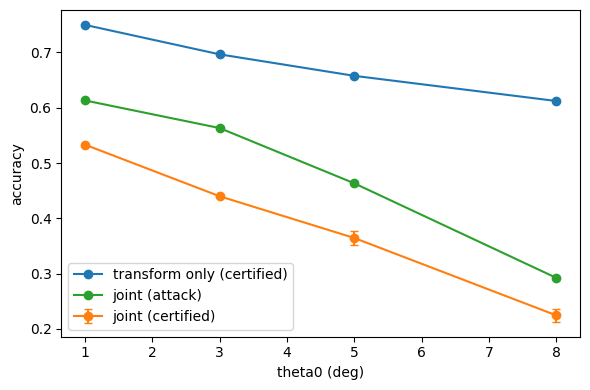

In [17]:
RUN_RANGE_STUDY = True
RANGE_SEEDS = 3 if not QUICK else 2
SEED_MIN_THETA = 5.0
LEVELS_STUDY = [(1.0, 0.1, 0.005), (3.0, 0.1, 0.005), (5.0, 0.1, 0.005), (8.0, 0.1, 0.005), (1.0, 0.25, 0.005), (1.0, 0.5, 0.005), (1.0, 0.1, 0.02)] \
    if not QUICK else [(1.0, 0.1, 0.005), (5.0, 0.1, 0.005), (1.0, 0.25, 0.005)]
rs = None
if RUN_RANGE_STUDY:
    rows = []
    for (th, ta, sg) in LEVELS_STUDY:
        vals = []
        for sd in range(RANGE_SEEDS if th >= SEED_MIN_THETA else 1):
            c = replace(cfg, theta_deg=th, tau=ta, sigma=sg, seed=sd)
            same = (th, ta, sg, sd) == (cfg.theta_deg, cfg.tau, cfg.sigma, cfg.seed)
            m = models["joint"] if same else train_model(c, "joint", Xtr, ytr, Xval, yval, tag=ckpt_tag(c, "joint"))
            vals.append(summarize(evaluate(m, c, Xte, yte, n_eval=cfg.n_abl), f"theta={th},tau={ta},sigma={sg}"))
        v = pd.DataFrame(vals)
        row = {k: v[k].mean() for k in ("clean", "cert_transform", "cert_patch", "cert_joint", "emp_robust_joint")}
        row.update(theta=th, tau=ta, sigma=sg, n_seeds=len(vals), cert_joint_std=float(v.cert_joint.std(ddof=1)) if len(vals) > 1 else 0.0,
                   cert_joint_ci=vals[0]["cert_joint_ci"] if len(vals) == 1 else "", bugs=int(v.bugs.sum()))
        rows.append(row)
        print(th, ta, sg, "certified", round(row["cert_joint"], 3), "+-", round(row["cert_joint_std"], 3), "empirical", round(row["emp_robust_joint"], 3), "bugs", row["bugs"])
    rs = pd.DataFrame(rows)
    assert rs.bugs.sum() == 0, "soundness bug in the range study"
    print(rs[["theta", "tau", "sigma", "n_seeds", "clean", "cert_transform", "cert_patch", "cert_joint", "cert_joint_std", "cert_joint_ci", "emp_robust_joint"]].round(3).to_string(index=False))
    rs.to_csv(f"{OUT}/range_study_{cfg.dataset}.csv")
    rt = rs[(rs.tau == 0.1) & (rs.sigma == 0.005)]
    plt.figure(figsize=(6, 4))
    plt.plot(rt.theta, rt.cert_transform, "o-", label="transform only (certified)")
    plt.errorbar(rt.theta, rt.cert_joint, yerr=rt.cert_joint_std, fmt="o-", capsize=3, label="joint (certified)")
    plt.plot(rt.theta, rt.emp_robust_joint, "o-", label="joint (attack)")
    plt.xlabel("theta0 (deg)"); plt.ylabel("accuracy"); plt.legend(); plt.tight_layout()
    plt.savefig(f"{OUT}/range_study_{cfg.dataset}.png", dpi=150); plt.show()

In [18]:
RUN_BUDGET_STUDY = True
if RUN_BUDGET_STUDY:
    rows = []
    for depth, nodes in (((6, 200), (8, 600), (10, 1500)) if not QUICK else ((3, 30), (5, 100))):
        c = replace(cfg, max_depth=depth, max_nodes=nodes)
        df = evaluate(models["joint"], c, Xte, yte, n_eval=min(cfg.n_abl, 100), do_attack=False)
        rows.append(dict(max_depth=depth, max_nodes=nodes, cert_joint=(df.clean & df.J).mean(), avg_nodes=df.loc[df.clean, "nodes_J"].mean(), avg_sec=df.loc[df.clean, "sec_J"].mean()))
    print(pd.DataFrame(rows).round(3).to_string(index=False))

RUN_GEOMETRIC_BENCH = True
gb = None
if RUN_GEOMETRIC_BENCH:
    rows = []
    for th in ((2.0, 5.0, 10.0, 20.0) if not QUICK else (2.0, 10.0)):
        c = replace(cfg, theta_deg=th, tau=0.0, sigma=0.0)
        m = train_model(c, "transform", Xtr, ytr, Xval, yval, tag=ckpt_tag(c, "transform"))
        def work(net, it, d, c=c):
            idx, x, y = it; x = x.unsqueeze(0).to(d); y = torch.tensor([int(y)], device=d)
            r = dict(clean=False, cert=False, atk=False)
            with torch.no_grad(): r["clean"] = bool(net(x).argmax(1) == y)
            if r["clean"]:
                r["cert"] = certify_cfg(net, x, y, c, "transform")[0]
                r["atk"] = attack_image(net, x, y, kbox(c), 0, c.order, c.att_kappa, c.att_stride, c.att_steps)
            return r
        res = pd.DataFrame(run_sharded(m, [(int(i), Xte[i], yte[i]) for i in EVAL_IDX[:cfg.n_abl]], work))
        rows.append(dict(theta=th, clean=res.clean.mean(), certified=(res.clean & res.cert).mean(), attack_upper_bound=(res.clean & ~res.atk).mean(), bugs=int((res.cert & res.atk).sum())))
        print(rows[-1])
    gb = pd.DataFrame(rows)
    assert gb.bugs.sum() == 0, "soundness bug in the rotation-only certificate"
    print(gb.round(3).to_string(index=False)); gb.to_csv(f"{OUT}/geometric_bench_{cfg.dataset}.csv")

RUN_CROWN_STUDY = False
if RUN_CROWN_STUDY:
    try:
        import auto_LiRPA
        rows = []
        for crown in (False, True):
            c = replace(cfg, use_crown=crown)
            df = evaluate(models["joint"], c, Xte, yte, n_eval=min(cfg.n_abl, 100), do_attack=False)
            rows.append(dict(use_crown=crown, cert_joint=(df.clean & df.J).mean(), avg_sec=df.loc[df.clean, "sec_J"].mean(), wall_s=df.attrs["sec"]))
        print(pd.DataFrame(rows).round(3).to_string(index=False))
    except ImportError:
        print("auto_LiRPA is not installed")

 max_depth  max_nodes  cert_joint  avg_nodes  avg_sec
         6        200        0.49      9.288    0.169
         8        600        0.51     11.650    0.216
        10       1500        0.53     14.350    0.267
[fmnist_transform_a_1eb17f9a] ep 1/30 ramp 0.00 loss 0.530 ce 0.530 rob 0.000 clean-acc 0.847 (2s)
[fmnist_transform_a_1eb17f9a] ep 5/30 ramp 0.30 loss 0.406 ce 0.323 rob 0.996 clean-acc 0.858 (24s)
[fmnist_transform_a_1eb17f9a] ep 10/30 ramp 0.80 loss 0.536 ce 0.375 rob 0.805 clean-acc 0.850 (59s)
[fmnist_transform_a_1eb17f9a] ep 15/30 ramp 1.00 loss 0.597 ce 0.415 rob 0.779 clean-acc 0.845 (93s)
[fmnist_transform_a_1eb17f9a] ep 20/30 ramp 1.00 loss 0.560 ce 0.400 rob 0.721 clean-acc 0.848 (128s)
[fmnist_transform_a_1eb17f9a] ep 25/30 ramp 1.00 loss 0.540 ce 0.391 rob 0.689 clean-acc 0.847 (161s)
[fmnist_transform_a_1eb17f9a] ep 30/30 ramp 1.00 loss 0.534 ce 0.390 rob 0.678 clean-acc 0.850 (195s)
{'theta': 2.0, 'clean': np.float64(0.8466666666666667), 'certified': np.float

## 15. Frontier

mean certified theta0* (deg):
k
1    4.366
2    3.755
3    1.932
Name: theta_eff, dtype: float64


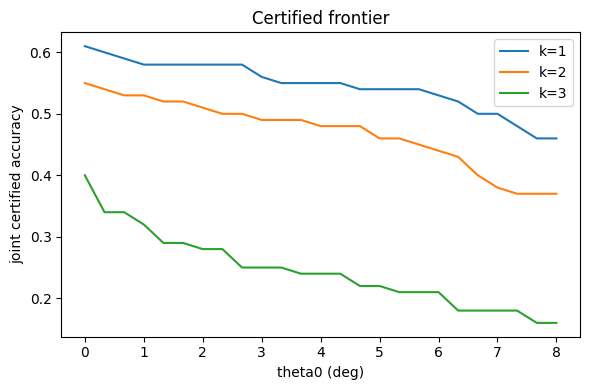

In [19]:
def frontier_item(model, item, dev, cfg, ks, theta_max, steps):
    idx, x, y = item; x = x.unsqueeze(0).to(dev); y = torch.tensor([int(y)], device=dev)
    with torch.no_grad(): clean = bool(model(x).argmax(1) == y)
    out = []
    for k in ks:
        ts = -1.0
        if clean:
            cert = lambda th: certify_cfg(model, x, y, replace(cfg, k=k, theta_deg=th), "joint")[0]
            if cert(theta_max): ts = theta_max
            elif cert(0.0):
                lo, hi = 0.0, theta_max
                for _ in range(steps):
                    mid = (lo + hi) / 2
                    if cert(mid): lo = mid
                    else: hi = mid
                ts = lo
        out.append(dict(idx=idx, k=k, clean=clean, theta_star=ts))
    return out

def frontier(model, cfg, ks, n_img, theta_max, steps=5):
    items = [(int(i), Xte[i], yte[i]) for i in EVAL_IDX[:n_img]]
    res = run_sharded(model, items, lambda m, it, d: frontier_item(m, it, d, cfg, ks, theta_max, steps))
    return pd.DataFrame([r for part in res for r in part])

ks = [1, 2, 3] if not QUICK else [1, 2]
TH_MAX = max(5.0, 4 * cfg.theta_deg)
fr = frontier(models["joint"], cfg, ks, n_img=10 if QUICK else 100, theta_max=TH_MAX, steps=3 if QUICK else 6)
fr["theta_eff"] = fr.theta_star.clip(lower=0)
print("mean certified theta0* (deg):"); print(fr.groupby("k").theta_eff.mean().round(3))
ths = np.linspace(0, TH_MAX, 25)
plt.figure(figsize=(6, 4))
for k, g in fr.groupby("k"): plt.plot(ths, [((g.theta_star >= t) & g.clean).mean() for t in ths], label=f"k={k}")
plt.xlabel("theta0 (deg)"); plt.ylabel("joint certified accuracy"); plt.legend(); plt.title("Certified frontier"); plt.tight_layout()
plt.savefig(f"{OUT}/frontier_{cfg.dataset}.png", dpi=150); plt.show(); fr.to_csv(f"{OUT}/frontier_{cfg.dataset}.csv")

## 16. Ablations

In [20]:
def ablate(model, cfg, grid, n=None, do_attack=False, do_mask=False):
    rows = []; n = n or cfg.n_abl
    for name, kw in grid:
        c = replace(cfg, **kw)
        df = evaluate(model, c, Xte, yte, n_eval=n, do_attack=do_attack, do_mask=do_mask)
        s = summarize(df, name); s.update(kw); s["S"] = effective_patch(c); rows.append(s)
        print(name, "-> joint", round(s["cert_joint"], 3), f"({df.attrs['sec']:.0f}s)")
    return pd.DataFrame(rows)

th_list = [0.0, cfg.theta_deg / 2, cfg.theta_deg, cfg.theta_deg * 2] if not QUICK else [0.0, cfg.theta_deg]
tau_list = [0.0, cfg.tau / 2, cfg.tau, cfg.tau * 2] if not QUICK else [0.0, cfg.tau]
grid  = [(f"k={k}", dict(k=k)) for k in ([1, 2, 3] if not QUICK else [1, 2])]
grid += [(f"theta={t}", dict(theta_deg=t)) for t in th_list]
grid += [(f"tau={t}", dict(tau=t)) for t in tau_list]
abl = ablate(models["joint"], cfg, grid)
abl.to_csv(f"{OUT}/ablation_{cfg.dataset}.csv"); print(abl[["model", "cert_transform", "cert_patch", "naive_both", "cert_joint", "avg_sec_J"]].round(3))

cfg_b = replace(cfg, order="b")
model_b = train_model(cfg_b, "joint", Xtr, ytr, Xval, yval, tag=ckpt_tag(cfg_b, "joint"))
ob = ablate(model_b, cfg_b, [(f"order_b={v}", dict(order_b=v)) for v in ("lemma", "footprint", "weighted")], do_attack=True)
assert ob.bugs.sum() == 0, "soundness bug in an order (b) certificate"
ob.to_csv(f"{OUT}/orderb_{cfg.dataset}.csv"); print(ob[["model", "cert_joint", "emp_robust_joint", "bugs", "avg_sec_J"]].round(3))

k=1 -> joint 0.627 (50s)
k=2 -> joint 0.507 (61s)
k=3 -> joint 0.26 (64s)
theta=0.0 -> joint 0.593 (28s)
theta=1.0 -> joint 0.537 (59s)
theta=2.0 -> joint 0.507 (61s)
theta=4.0 -> joint 0.457 (86s)
tau=0.0 -> joint 0.593 (27s)
tau=0.05 -> joint 0.557 (42s)
tau=0.1 -> joint 0.507 (61s)
tau=0.2 -> joint 0.437 (111s)
        model  cert_transform  cert_patch  naive_both  cert_joint  avg_sec_J
0         k=1           0.703       0.777       0.700       0.627      0.243
1         k=2           0.703       0.660       0.623       0.507      0.333
2         k=3           0.703       0.407       0.397       0.260      0.305
3   theta=0.0           0.783       0.660       0.653       0.593      0.128
4   theta=1.0           0.740       0.660       0.640       0.537      0.258
5   theta=2.0           0.703       0.660       0.623       0.507      0.332
6   theta=4.0           0.687       0.660       0.617       0.457      0.451
7     tau=0.0           0.807       0.660       0.657       0.593   

## 17. Window comparison and order (b)

In [21]:
H0, W0 = Xte.shape[-2:]
ks = [1, 2, 3] if not QUICK else [1, 2]
ks_window = [1, 2, 3, 4, 5] if not QUICK else [1, 2]

def paired_diff_ci(a, b, n_boot=2000):
    d = np.asarray(b, float) - np.asarray(a, float); rng = np.random.RandomState(0)
    boots = [d[rng.randint(0, len(d), len(d))].mean() for _ in range(n_boot)]
    return d.mean(), float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))

rows = []
for k in ks_window:
    c = replace(cfg, k=k)
    mj = models["joint"] if k == cfg.k else train_model(c, "joint", Xtr, ytr, Xval, yval, tag=ckpt_tag(c, "joint"))
    mm = models["mask"] if k == cfg.k else train_model(c, "mask", Xtr, ytr, Xval, yval, tag=ckpt_tag(c, "mask"))
    dj = evaluate(mj, c, Xte, yte, n_eval=cfg.n_abl, do_attack=False)
    dm = evaluate(mm, c, Xte, yte, n_eval=cfg.n_abl, do_attack=False, do_mask=True)
    fr_ok, mk_ok = (dj.clean & dj.J).values, dm.J_mask.values
    d, lo, hi = paired_diff_ci(fr_ok, mk_ok)
    rows.append(dict(k=k, free_window=fr_ok.mean(), mask_window=mk_ok.mean(), mask_minus_free=d, ci_lo=lo, ci_hi=hi, mask_clean_defended=dm.clean_pc.mean(), mask_bugs=int(dm.bug_mask.sum())))
fm = pd.DataFrame(rows); print(fm.round(3)); fm.to_csv(f"{OUT}/free_vs_mask_{cfg.dataset}.csv")
assert fm.mask_bugs.sum() == 0, "soundness bug in the mask certificate"

def mean_footprint_area(c):
    node = make_node(torch.zeros(1, 1, H0, W0), kbox(c)); locs = all_locs(H0, W0, c.k)
    return float(footprint(node, locs, c.k).flatten(1).sum(1).double().mean())

rows = []
for k in ks:
    c = replace(cfg_b, k=k, order_b="weighted")
    mb = model_b if k == cfg.k else train_model(c, "joint", Xtr, ytr, Xval, yval, tag=ckpt_tag(c, "joint"))
    df = evaluate(mb, c, Xte, yte, n_eval=cfg.n_abl, do_attack=False)
    ct, cj = (df.clean & df["T"]).mean(), (df.clean & df.J).mean()
    rows.append(dict(k=k, footprint_area=mean_footprint_area(c), cert_transform=ct, cert_joint=cj, drop=ct - cj))
il = pd.DataFrame(rows); print(il.round(3)); il.to_csv(f"{OUT}/orderb_vs_k_{cfg.dataset}.csv")

RUN_STRIDE_SWEEP = False
if RUN_STRIDE_SWEEP:
    rows = []
    for st in (2, 3, 4, 6):
        c = replace(cfg, mask_stride=st)
        mm = models["mask"] if st == cfg.mask_stride else train_model(c, "mask", Xtr, ytr, Xval, yval, tag=ckpt_tag(c, "mask"))
        df = evaluate(mm, c, Xte, yte, n_eval=cfg.n_abl, do_attack=False, do_mask=True)
        rows.append(dict(stride=st, clean_defended=df.clean_pc.mean(), cert_mask=df.J_mask.mean(), sec_per_img=df.sec_M.mean()))
    print(pd.DataFrame(rows).round(3))

[fmnist_joint_a_1be4a9b3] ep 1/30 ramp 0.00 loss 0.531 ce 0.531 rob 0.000 clean-acc 0.851 (2s)
[fmnist_joint_a_1be4a9b3] ep 5/30 ramp 0.30 loss 0.442 ce 0.344 rob 1.132 clean-acc 0.868 (42s)
[fmnist_joint_a_1be4a9b3] ep 10/30 ramp 0.80 loss 0.631 ce 0.428 rob 0.969 clean-acc 0.839 (106s)
[fmnist_joint_a_1be4a9b3] ep 15/30 ramp 1.00 loss 0.720 ce 0.493 rob 0.948 clean-acc 0.826 (170s)
[fmnist_joint_a_1be4a9b3] ep 20/30 ramp 1.00 loss 0.683 ce 0.476 rob 0.890 clean-acc 0.825 (234s)
[fmnist_joint_a_1be4a9b3] ep 25/30 ramp 1.00 loss 0.663 ce 0.466 rob 0.860 clean-acc 0.834 (298s)
[fmnist_joint_a_1be4a9b3] ep 30/30 ramp 1.00 loss 0.656 ce 0.466 rob 0.846 clean-acc 0.834 (362s)
[fmnist_mask_a_8631541c] ep 1/30 ramp 0.00 loss 0.586 ce 0.586 rob 0.000 clean-acc 0.851 (2s)
[fmnist_mask_a_8631541c] ep 5/30 ramp 0.30 loss 0.500 ce 0.386 rob 1.310 clean-acc 0.859 (41s)
[fmnist_mask_a_8631541c] ep 10/30 ramp 0.80 loss 0.685 ce 0.460 rob 1.059 clean-acc 0.822 (103s)
[fmnist_mask_a_8631541c] ep 15/30

## 18. Summary

model	clean	cert_joint	emp_robust_joint
standard	0.916	0.0	0.338
transform	0.858	0.356	0.436
patch	0.914	0.0	0.684
joint	0.84	0.506	0.584
mask	0.852	0.168	0.246

joint model, 500 images: certified 0.506 [0.461, 0.551], empirical upper bound 0.584
tightness gap  joint +0.078  transform +0.082  patch +0.006
interaction cost (min of single-threat certificates minus joint): +0.184
naive over-claim rate by model: {'transform': 0.092, 'patch': 0.0, 'joint': 0.072, 'mask': 0.052}
empirical joint-robust accuracy by training mode: {'standard': 0.338, 'transform': 0.436, 'patch': 0.684, 'joint': 0.584, 'mask': 0.246}
seeds (3): certified joint 0.517 +- 0.015
calibrated range: theta 2.0 deg, tau 0.1 px, sigma 0.005, patch 2x2
 theta  tau  sigma  n_seeds  cert_joint  cert_joint_std  emp_robust_joint
   1.0 0.10  0.005        1       0.533           0.000             0.613
   3.0 0.10  0.005        1       0.440           0.000             0.563
   5.0 0.10  0.005        3       0.364           0.0

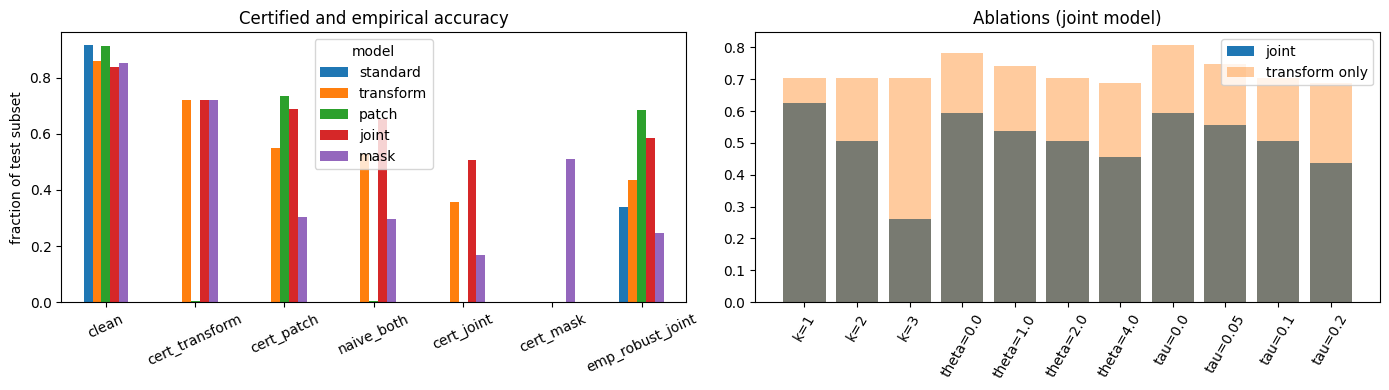

saved /kaggle/working/results_fmnist.zip


In [22]:
def ci_str(row, col): return row[col + "_ci"] if col + "_ci" in row else ""
j, s = main.loc["joint"], main.loc["standard"]
print("model", "clean", "cert_joint", "emp_robust_joint", sep="\t")
for name in main.index: print(name, round(main.loc[name, "clean"], 3), round(main.loc[name, "cert_joint"], 3), round(main.loc[name, "emp_robust_joint"], 3), sep="\t")
print(f"\njoint model, {int(j.n)} images: certified {j.cert_joint:.3f} {j.cert_joint_ci}, empirical upper bound {j.emp_robust_joint:.3f}")
print(f"tightness gap  joint {j.emp_robust_joint - j.cert_joint:+.3f}  transform {j.emp_robust_transform - j.cert_transform:+.3f}  patch {j.emp_robust_patch - j.cert_patch:+.3f}")
print(f"interaction cost (min of single-threat certificates minus joint): {min(j.cert_transform, j.cert_patch) - j.cert_joint:+.3f}")
print("naive over-claim rate by model:", {m: round(float(main.loc[m, "naive_overclaim"]), 3) for m in ("transform", "patch", "joint", "mask")})
print("empirical joint-robust accuracy by training mode:", {m: round(float(main.loc[m, "emp_robust_joint"]), 3) for m in main.index})
print(f"seeds ({cfg.n_seeds}): certified joint {agg.loc['cert_joint', 'mean']:.3f} +- {agg.loc['cert_joint', 'std']:.3f}")
print(f"calibrated range: theta {cfg.theta_deg} deg, tau {cfg.tau} px, sigma {cfg.sigma}, patch {cfg.k}x{cfg.k}")
if rs is not None: print(rs[["theta", "tau", "sigma", "n_seeds", "cert_joint", "cert_joint_std", "emp_robust_joint"]].round(3).to_string(index=False))
if gb is not None: print(gb.round(3).to_string(index=False))
print(fm.round(3).to_string(index=False))
cross = fm[fm.mask_window >= fm.free_window]
print("mask window matches or exceeds the free window from k =", int(cross.k.min()) if len(cross) else "none in the tested range")
sig = fm[fm.ci_lo > 0]
print("mask window significantly better (paired 95% bootstrap interval) at k =", sig.k.tolist() if len(sig) else "none in the tested range")
print(il.round(3).to_string(index=False))

cols = ["clean", "cert_transform", "cert_patch", "naive_both", "cert_joint", "cert_mask", "emp_robust_joint"]
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
main[cols].T.plot.bar(ax=ax[0], rot=25); ax[0].set_ylabel("fraction of test subset"); ax[0].set_title("Certified and empirical accuracy")
a = abl[abl.model.str.startswith(("k=", "theta=", "tau="))]
ax[1].bar(a.model, a.cert_joint, label="joint"); ax[1].bar(a.model, a.cert_transform, alpha=0.4, label="transform only")
ax[1].tick_params(axis="x", rotation=60); ax[1].set_title("Ablations (joint model)"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{OUT}/results_{cfg.dataset}.png", dpi=150); plt.show()
json.dump({"cfg": asdict(cfg), "main": main.reset_index().to_dict("records"), "seeds": seeds.reset_index().to_dict("records")},
          open(f"{OUT}/summary_{cfg.dataset}.json", "w"), indent=1, default=float)

import zipfile, glob
with open(f"{OUT}/results_tables.txt", "w") as f:
    for name, t in (("main", main.T), ("seeds", seeds), ("range study", rs), ("geometric-only benchmark", gb), ("window comparison", fm),
                    ("order (b) cost", il), ("order (b) variants", ob), ("ablations", abl)):
        if t is not None: f.write(f"== {name} ==\n{t.round(3).to_string()}\n\n")
with zipfile.ZipFile(f"{OUT}/results_{cfg.dataset}.zip", "w") as z:
    for p in sorted(glob.glob(f"{OUT}/*.csv") + glob.glob(f"{OUT}/*.png") + glob.glob(f"{OUT}/*.json") + glob.glob(f"{OUT}/results_tables.txt")):
        z.write(p, os.path.basename(p))
print("saved", f"{OUT}/results_{cfg.dataset}.zip")

## Notes

* Certificates are lower bounds on robust accuracy and attacks are upper bounds; both use the same fixed random subset of the test set, and floating-point rounding is not modelled in the bounds.
* The certified geometric range is small (printed in the summary). Dedicated geometric verifiers such as DeepG and Super-DeepG certify much larger transformation ranges; this notebook does not compete with them on range.
* The mask certificate applies to the PatchCleanser-defended classifier, not to the raw model.
* The rotation-only benchmark (no patch, no translation or scale) is the closest reference point to dedicated geometric verifiers; compare it with their published numbers before drawing conclusions about verifier strength.
* `DATASET` also accepts "fmnist" and "cifar10"; output files carry the dataset name. The CIFAR-10 option has not been run.
* GPU kernels are non-deterministic: repeating a run with the same seed changes certified accuracy by about 0.015 at n=500, and by more at large ranges.
* The window comparison and the order (b) cost table train a model for each patch size. The ablation and frontier tables evaluate one fixed model, trained at the configured patch size, at other sizes.